# VoltRelay Energy — Network Performance, Unit Economics & Rider Retention
### Gradient Learnings 1-Day Data Analytics Hackathon · Complete Analysis Notebook

**Author:** Vedaant Gupta · IIT Kharagpur
**Stack:** DuckDB (all heavy SQL on 3.88M-row event log) + Pandas/Matplotlib/Seaborn (aggregates only)

**How to run:** Place the 8 dataset CSVs (`.csv` or `.csv.gz`) in the same directory as this
notebook (or in `./data/`, or upload to `/content/` on Colab) and run all cells top-to-bottom.
No cell loads a large table into Pandas; every join/window/aggregation runs inside DuckDB,
so the notebook stays well under Colab's 12 GB RAM.

**Structure**
1. Data Hygiene Audit — 9 cleaning rules, each *validated against the data* before being applied
2. Q1 Network growth vs contribution-margin compression
3. Q2 Where service failures concentrate (stations × hours × weather)
4. Q3 Station equipment, expansion waves, competitor entry
5. Q4 Battery cohorts, the Kyron failure, delivered range
6. Q5 Pricing: base hike, 2-city peak pilot (DiD), fleet-partner economics
7. Q6 New-rider retention root causes
8. The 4-way budget decision — quantified
9. Executive summary figure for LinkedIn

In [1]:
# ── 0.1 Environment ───────────────────────────────────────────────
import sys, subprocess, importlib
for pkg in ["duckdb"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, json, glob
import duckdb
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.ticker import FuncFormatter, PercentFormatter

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Executive palette (consistent across every chart)
NAVY, BLUE, RED, AMBER, GREEN = "#0F172A", "#2563EB", "#DC2626", "#D97706", "#059669"
GREY = "#94A3B8"
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY, "axes.titleweight": "bold",
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10})

os.makedirs("figures", exist_ok=True)
KEY = {}   # every headline number lands here -> key_numbers.json

def title2(ax, finding, sub):
    ax.set_title(finding + "\n", fontsize=12, fontweight="bold", color=NAVY, loc="left")
    ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=8.5, color=GREY)

def inr(x, pos=None):
    if abs(x) >= 1e7:  return f"₹{x/1e7:.1f} Cr"
    if abs(x) >= 1e5:  return f"₹{x/1e5:.1f} L"
    if abs(x) >= 1e3:  return f"₹{x/1e3:.0f}k"
    return f"₹{x:.0f}"

def savefig(fig, name):
    fig.savefig(f"figures/{name}.png", bbox_inches="tight")

MILESTONES = [  # vertical annotation lines for time-series charts
    ("2024-07-01", "Base price +8%"),
    ("2024-10-01", "Peak pilot (BLR+PUN)"),
    ("2024-11-01", "ZipDrop 28% discount"),
    ("2025-01-15", "Competitor entry"),
    ("2025-06-15", "Kyron retirement"),
]
def add_milestones(ax, labels=True, y=0.98):
    for i,(d,l) in enumerate(MILESTONES):
        ax.axvline(pd.Timestamp(d), color=GREY, ls="--", lw=0.9, alpha=0.8)
        if labels:
            ax.text(pd.Timestamp(d), y, " "+l, transform=ax.get_xaxis_transform(),
                    rotation=90, va="top", ha="right", fontsize=7, color=GREY)
print("Environment ready. DuckDB", duckdb.__version__)

Environment ready. DuckDB 2.0.0


In [2]:
# ── 0.2 File locator: finds the 8 tables as .csv or .csv.gz ──────
TABLES = ["swap_events","station_hourly_status","riders","batteries",
          "support_tickets","stations","city_daily_context","fleet_partners"]
SEARCH_DIRS = [".","data","/content","/content/data","/content/drive/MyDrive",
               "/content/drive/MyDrive/voltrelay"]

def locate(table):
    for d in SEARCH_DIRS:
        for ext in (".csv", ".csv.gz"):
            p = os.path.join(d, table + ext)
            if os.path.exists(p):
                return p
    hits = glob.glob(f"**/{table}.csv*", recursive=True)
    if hits: return hits[0]
    raise FileNotFoundError(f"{table}.csv(.gz) not found — upload it next to this notebook")

PATHS = {t: locate(t) for t in TABLES}
for t,p in PATHS.items():
    print(f"{t:<24} -> {p}  ({os.path.getsize(p)/1e6:,.1f} MB)")

swap_events              -> data/swap_events.csv  (728.7 MB)
station_hourly_status    -> data/station_hourly_status.csv  (108.4 MB)
riders                   -> data/riders.csv  (2.1 MB)
batteries                -> data/batteries.csv  (0.6 MB)
support_tickets          -> data/support_tickets.csv  (6.5 MB)
stations                 -> data/stations.csv  (0.0 MB)
city_daily_context       -> data/city_daily_context.csv  (0.2 MB)
fleet_partners           -> data/fleet_partners.csv  (0.0 MB)


In [3]:
# ── 0.3 DuckDB connection + robust CSV registration ──────────────
# Disk-backed DB so large intermediate tables spill to disk, never to RAM.
if os.path.exists("voltrelay.duckdb"): os.remove("voltrelay.duckdb")
con = duckdb.connect("voltrelay.duckdb")
con.execute("PRAGMA threads=4")

def register(table, path):
    """read_csv_auto first; fall back to explicit dialect (some DuckDB builds
    fail to sniff swap_events despite it being clean comma-separated UTF-8)."""
    for opts in ["", ", delim=',', header=true, quote='', escape='', strict_mode=false"]:
        try:
            con.execute(f"CREATE OR REPLACE VIEW {table}_raw AS "
                        f"SELECT * FROM read_csv('{path}'{opts})")
            con.execute(f"SELECT * FROM {table}_raw LIMIT 1")
            return
        except Exception as e:
            last = e
    raise last

for t,p in PATHS.items(): register(t,p)

raw_counts = con.execute("SELECT " + ", ".join(
    f"(SELECT COUNT(*) FROM {t}_raw) AS {t}" for t in TABLES)).df().T
raw_counts.columns=["rows"]; print(raw_counts)
KEY["raw_rows"] = raw_counts["rows"].to_dict()

                          rows
swap_events            3877013
station_hourly_status  1487712
riders                   20000
batteries                 6500
support_tickets          44000
stations                   152
city_daily_context        3282
fleet_partners              12


## 1 · Data Hygiene Audit — nine rules, each tested before trusted
A cleaning rule applied blindly is just another way to corrupt data, so for every rule below
we first **measure the problem**, then apply the fix, and log exact affected-row counts into a
single Hygiene Summary Table. Two of the brief's assumed defects turned out to be
*different in the data than described* — both are documented honestly below.

In [4]:
# ── Rule 1: Test stations (STN-TST-*) ────────────────────────────
HY = []  # hygiene log: (rule, table, rows_affected, action)
tst = con.execute("""
SELECT 'stations' t, COUNT(*) n FROM stations_raw WHERE station_id LIKE 'STN-TST%'
UNION ALL SELECT 'swap_events', COUNT(*) FROM swap_events_raw WHERE station_id LIKE 'STN-TST%'
UNION ALL SELECT 'station_hourly_status', COUNT(*) FROM station_hourly_status_raw WHERE station_id LIKE 'STN-TST%'
UNION ALL SELECT 'support_tickets', COUNT(*) FROM support_tickets_raw WHERE station_id LIKE 'STN-TST%'
""").df()
print(tst)
for _,r in tst.iterrows():
    HY.append(("1. Exclude test stations", r["t"], int(r["n"]), "rows removed"))
KEY["test_station_rows"] = tst.set_index("t")["n"].to_dict()

con.execute("""CREATE OR REPLACE VIEW stations_c AS
  SELECT * FROM stations_raw WHERE station_id NOT LIKE 'STN-TST%'""")
con.execute("""CREATE OR REPLACE VIEW hourly_c0 AS
  SELECT * FROM station_hourly_status_raw WHERE station_id NOT LIKE 'STN-TST%'""")

                       t      n
0               stations      2
1            swap_events  62031
2  station_hourly_status  26256
3        support_tickets    535


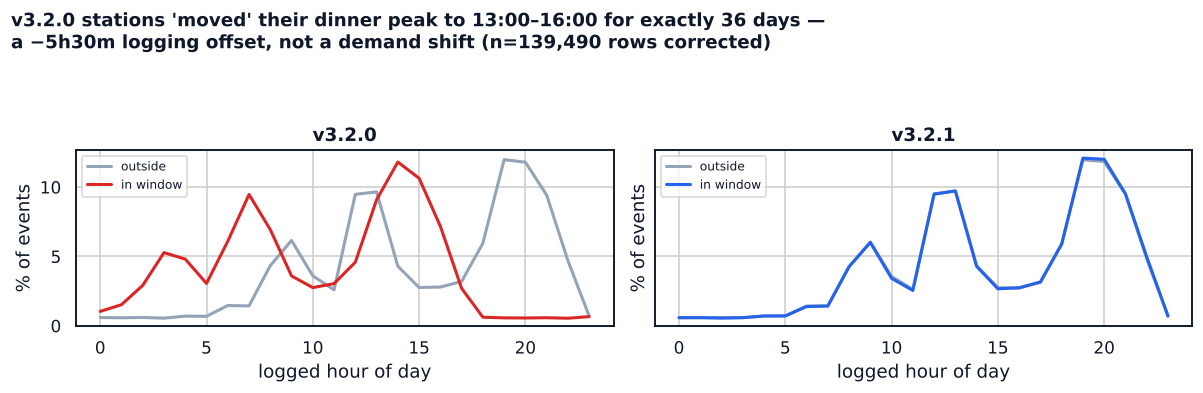

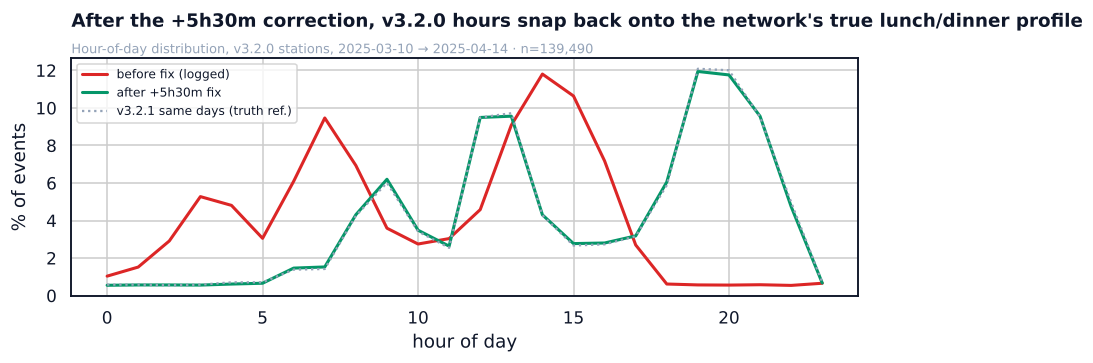

Edge note: the window is defined on logged dates, so true times during the first 5.5h of 2025-03-10 and the last 5.5h of 2025-04-14 remain ambiguous (~0.5% of fixed rows).


In [5]:
# ── Rule 2: Firmware v3.2.0 timezone bug — prove it, then fix it ─
# Claim: v3.2.0 stations logged event_ts 5h30m early between 2025-03-10 and 2025-04-14.
# Proof: compare hour-of-day profiles inside vs outside the window, per firmware.
prof = con.execute("""
SELECT station_firmware fw,
  CASE WHEN event_ts::DATE BETWEEN DATE '2025-03-10' AND DATE '2025-04-14'
       THEN 'in window' ELSE 'outside' END w,
  EXTRACT(hour FROM event_ts)::INT hr, COUNT(*) n
FROM swap_events_raw
WHERE event_ts::DATE BETWEEN DATE '2025-01-20' AND DATE '2025-05-31'
GROUP BY 1,2,3""").df()

n_bug = con.execute("""SELECT COUNT(*) FROM swap_events_raw
  WHERE station_firmware='v3.2.0'
    AND event_ts::DATE BETWEEN DATE '2025-03-10' AND DATE '2025-04-14'""").fetchone()[0]
KEY["firmware_rows_fixed"] = n_bug
HY.append(("2. Firmware v3.2.0 ts +5h30m", "swap_events", n_bug, "timestamps corrected"))

fig, axes = plt.subplots(1, 2, figsize=(11,3.6), sharey=True)
for ax, fw in zip(axes, ["v3.2.0","v3.2.1"]):
    for w, c in [("outside",GREY), ("in window", RED if fw=="v3.2.0" else BLUE)]:
        d = prof[(prof.fw==fw)&(prof.w==w)].sort_values("hr")
        share = d.n/d.n.sum()*100
        ax.plot(d.hr, share, color=c, lw=2, label=w)
    ax.set_xlabel("logged hour of day"); ax.set_ylabel("% of events"); ax.legend(fontsize=8)
    ax.set_title(fw, color=NAVY)
fig.suptitle("v3.2.0 stations 'moved' their dinner peak to 13:00–16:00 for exactly 36 days —\n"
             f"a −5h30m logging offset, not a demand shift (n={n_bug:,} rows corrected)",
             fontweight="bold", color=NAVY, x=0.01, ha="left")
fig.tight_layout(rect=[0,0,1,0.88]); savefig(fig,"01_firmware_before"); plt.show()

# Fix: single canonical timestamp used by EVERYTHING downstream
con.execute("""CREATE OR REPLACE VIEW swaps_ts AS
SELECT *,
  CASE WHEN station_firmware='v3.2.0'
        AND event_ts::DATE BETWEEN DATE '2025-03-10' AND DATE '2025-04-14'
       THEN event_ts + INTERVAL '5 hours 30 minutes' ELSE event_ts END AS ts
FROM swap_events_raw""")

# After-fix visual proof
after = con.execute("""
SELECT EXTRACT(hour FROM ts)::INT hr, COUNT(*) n FROM swaps_ts
WHERE station_firmware='v3.2.0'
  AND event_ts::DATE BETWEEN DATE '2025-03-10' AND DATE '2025-04-14'
GROUP BY 1 ORDER BY 1""").df()
before = prof[(prof.fw=="v3.2.0")&(prof.w=="in window")].sort_values("hr")
ref    = prof[(prof.fw=="v3.2.1")&(prof.w=="in window")].sort_values("hr")
fig, ax = plt.subplots(figsize=(8,3.4))
ax.plot(before.hr, before.n/before.n.sum()*100, color=RED,  lw=2, label="before fix (logged)")
ax.plot(after.hr,  after.n/after.n.sum()*100,  color=GREEN, lw=2, label="after +5h30m fix")
ax.plot(ref.hr,    ref.n/ref.n.sum()*100, color=GREY, lw=1.5, ls=":", label="v3.2.1 same days (truth ref.)")
title2(ax, "After the +5h30m correction, v3.2.0 hours snap back onto the network's true lunch/dinner profile",
       f"Hour-of-day distribution, v3.2.0 stations, 2025-03-10 → 2025-04-14 · n={n_bug:,}")
ax.set_xlabel("hour of day"); ax.set_ylabel("% of events"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig,"02_firmware_after"); plt.show()
print("Edge note: the window is defined on logged dates, so true times during the first "
      "5.5h of 2025-03-10 and the last 5.5h of 2025-04-14 remain ambiguous (~0.5% of fixed rows).")

In [6]:
# ── Rule 3: Near-duplicate retries — the claim vs the data ───────
# Claimed: offline_batch retries duplicate the same attempt within seconds,
# keyed on (rider, station, type, battery_in, battery_out).
dup_strict = con.execute("""
WITH g AS (SELECT sync_mode, ts - LAG(ts) OVER (
    PARTITION BY rider_id, station_id, event_type,
                 COALESCE(battery_in_id,''), COALESCE(battery_out_id,'')
    ORDER BY ts) gap FROM swaps_ts)
SELECT COUNT(*) FROM g WHERE gap <= INTERVAL 180 SECOND""").fetchone()[0]

dup_loose = con.execute("""
WITH g AS (SELECT sync_mode, ts - LAG(ts) OVER (
    PARTITION BY rider_id, station_id, event_type ORDER BY ts) gap FROM swaps_ts)
SELECT sync_mode, COUNT(*) FILTER (WHERE gap <= INTERVAL 180 SECOND) dups, COUNT(*) n
FROM g GROUP BY 1""").df()
print(f"Duplicates on the brief's strict key (incl. battery ids): {dup_strict}")
print(dup_loose)

# FINDING: the strict key finds ZERO — retry rows carry different/NULL battery ids.
# On (rider, station, event_type) within 180s we find ~5.7k bursts; two completed
# swaps by one rider at one station inside 3 minutes is physically impossible
# (a swap+queue cycle takes minutes), so we keep the FIRST event of each burst.
# The 'concentrated in offline_batch' claim is REFUTED: the dup rate is ~0.15%
# in BOTH sync modes.
rate = (dup_loose.assign(r=lambda d: 100*d.dups/d.n)[["sync_mode","dups","n","r"]])
print(rate.to_string(index=False))

con.execute("""CREATE OR REPLACE VIEW swaps_dedup AS
WITH g AS (SELECT *, ts - LAG(ts) OVER (
    PARTITION BY rider_id, station_id, event_type ORDER BY ts) gap FROM swaps_ts)
SELECT * EXCLUDE (gap) FROM g WHERE gap IS NULL OR gap > INTERVAL 180 SECOND""")
n_dedup = int(dup_loose.dups.sum())
KEY["dedup_removed"] = n_dedup
KEY["dedup_rate_by_mode"] = {r.sync_mode: round(100*r.dups/r.n,3) for r in dup_loose.itertuples()}
HY.append(("3. Retry bursts ≤180s (keep first)", "swap_events", n_dedup,
           "rows removed (strict battery-key found 0; see note)"))

Duplicates on the brief's strict key (incl. battery ids): 0
       sync_mode  dups        n
0  offline_batch   880   591114
1       realtime  4840  3285899
    sync_mode  dups       n        r
offline_batch   880  591114 0.148871
     realtime  4840 3285899 0.147296


In [7]:
# ── Rule 4: home_city canonicalisation via home_zone prefix ──────
raw_cities = con.execute("""SELECT home_city, COUNT(*) n FROM riders_raw
                            GROUP BY 1 ORDER BY 1""").df()
print(f"{len(raw_cities)} distinct raw spellings:")
print(raw_cities.to_string(index=False))

con.execute("""CREATE OR REPLACE VIEW riders_c AS
SELECT r.*,
  CASE SUBSTR(home_zone,1,3)
    WHEN 'BLR' THEN 'Bengaluru' WHEN 'DEL' THEN 'Delhi NCR'
    WHEN 'HYD' THEN 'Hyderabad' WHEN 'PUN' THEN 'Pune'
    WHEN 'MUM' THEN 'Mumbai'    WHEN 'JAI' THEN 'Jaipur'
    ELSE CASE  -- regex fallback if zone ever missing
      WHEN REGEXP_MATCHES(LOWER(TRIM(home_city)), 'b(e|a)ng|blr')         THEN 'Bengaluru'
      WHEN REGEXP_MATCHES(LOWER(TRIM(home_city)), 'delhi|gurgaon|noida')  THEN 'Delhi NCR'
      WHEN REGEXP_MATCHES(LOWER(TRIM(home_city)), 'hyd')                  THEN 'Hyderabad'
      WHEN REGEXP_MATCHES(LOWER(TRIM(home_city)), 'pun')                  THEN 'Pune'
      WHEN REGEXP_MATCHES(LOWER(TRIM(home_city)), 'mum|bombay')           THEN 'Mumbai'
      WHEN REGEXP_MATCHES(LOWER(TRIM(home_city)), 'jai')                  THEN 'Jaipur'
    END END AS city
FROM riders_raw r""")
chk = con.execute("""SELECT city, COUNT(*) n, COUNT(DISTINCT home_city) raw_variants
                     FROM riders_c GROUP BY 1 ORDER BY 2 DESC""").df()
print(chk.to_string(index=False))
n_dirty = int(raw_cities[~raw_cities.home_city.isin(
    ['Bengaluru','Delhi NCR','Hyderabad','Pune','Mumbai','Jaipur'])].n.sum())
KEY["dirty_city_riders"] = n_dirty
HY.append(("4. home_city standardised (21 spellings → 6 cities)", "riders", n_dirty, "values rewritten"))

21 distinct raw spellings:
 home_city    n
       BLR   53
 Bangalore   32
 Bengaluru 4175
    Bombay   53
     Delhi   25
 Delhi NCR 3783
   Gurgaon   36
       HYD   31
       Hyd   31
 Hyderabad 3396
       JAI   41
    Jaipur 2446
       MUM   49
    Mumbai 2772
 New Delhi   42
       PUN   43
      Pune 2843
bengaluru    50
 hyderabad   27
    jaipur   29
      pune   43
     city    n  raw_variants
Bengaluru 4310             4
Delhi NCR 3886             4
Hyderabad 3485             4
     Pune 2929             3
   Mumbai 2874             3
   Jaipur 2516             3


In [8]:
# ── Rules 5+6: sensor caps, km outliers, completed-vs-failed split ─
drift = con.execute("""SELECT
  COUNT(*) FILTER (WHERE soh_in_pct >100 OR soh_out_pct >100
                      OR soc_in_pct >100 OR soc_out_pct >100) pct_gt100,
  COUNT(*) FILTER (WHERE km_since_last_swap <= 0.5) km_low,
  COUNT(*) FILTER (WHERE km_since_last_swap > 150)  km_high
FROM swaps_dedup""").df().iloc[0]
print(drift)

con.execute("""CREATE OR REPLACE TABLE swaps_clean AS
SELECT * EXCLUDE (soc_in_pct, soh_in_pct, soc_out_pct, soh_out_pct),
  LEAST(soc_in_pct, 100.0)  AS soc_in_pct,
  LEAST(soh_in_pct, 100.0)  AS soh_in_pct,
  LEAST(soc_out_pct,100.0)  AS soc_out_pct,
  LEAST(soh_out_pct,100.0)  AS soh_out_pct,
  CASE WHEN km_since_last_swap <= 0.5 OR km_since_last_swap > 150
       THEN NULL ELSE km_since_last_swap END AS km_clean,
  (event_type = 'swap_completed') AS is_completed
FROM swaps_dedup
WHERE station_id NOT LIKE 'STN-TST%'""")      # Rule 1 applied to events here

n_clean, n_comp = con.execute(
  "SELECT COUNT(*), COUNT(*) FILTER (WHERE is_completed) FROM swaps_clean").fetchone()
KEY["clean_rows"], KEY["completed_swaps"] = n_clean, n_comp
KEY["failed_attempts"] = n_clean - n_comp
KEY["overall_failure_rate_pct"] = round(100*(n_clean-n_comp)/n_clean, 2)
HY.append(("5a. SoC/SoH capped at 100", "swap_events", int(drift.pct_gt100), "values capped"))
HY.append(("5b. km ≤0.5 or >150 → NULL (odometer resets/drift)", "swap_events",
           int(drift.km_low + drift.km_high), "values nulled"))
HY.append(("6. Completed vs failed split", "swap_events", n_clean - n_comp,
           f"failed/abandoned attempts flagged ({KEY['overall_failure_rate_pct']}%)"))
print(f"Clean events: {n_clean:,} · completed {n_comp:,} · "
      f"failure rate {KEY['overall_failure_rate_pct']}%")

pct_gt100    9749
km_low       7808
km_high      7701
Name: 0, dtype: int64


Clean events: 3,809,346 · completed 3,581,061 · failure rate 5.99%


In [9]:
# ── Rule 7: telemetry gaps — never COALESCE to zero ──────────────
tel = con.execute("""
SELECT s.connectivity_tier, h.telemetry_status, COUNT(*) n,
  ROUND(100.0*COUNT(*)/SUM(COUNT(*)) OVER (PARTITION BY s.connectivity_tier),2) pct,
  COUNT(*) FILTER (WHERE h.charged_2w_min IS NULL) null_inventory
FROM hourly_c0 h JOIN stations_c s USING(station_id)
GROUP BY 1,2 ORDER BY 1,2""").df()
print(tel.to_string(index=False))
n_missing = int(tel[tel.telemetry_status=="missing"].n.sum())
KEY["telemetry_missing_hours"] = n_missing
# 'missing' rows have NULL inventory & grid_kwh. A COALESCE(...,0) would fabricate
# ~9.4k fake stockout-hours — ALL at connectivity_tier='poor' stations, which would
# then look even worse than they are. We exclude those hours from inventory math
# and keep NULLs NULL. 'partial' rows carry complete values and are retained.
con.execute("""CREATE OR REPLACE VIEW hourly_c AS
  SELECT * FROM hourly_c0 WHERE telemetry_status IN ('ok','partial')""")
HY.append(("7. Telemetry 'missing' hours excluded from inventory math",
           "station_hourly_status", n_missing, "rows excluded (all at 'poor' tier)"))

connectivity_tier telemetry_status      n   pct  null_inventory
             fair               ok 267660 96.05               0
             fair          partial  11004  3.95               0
             good               ok 938666 98.99               0
             good          partial   9550  1.01               0
             poor          missing   9384  4.00            9384
             poor               ok 208999 89.10               0
             poor          partial  16193  6.90               0


In [10]:
# ── Rule 8: ticket dedup + CSAT is Missing-Not-At-Random ─────────
tk = con.execute("SELECT resolution_status, COUNT(*) n FROM support_tickets_raw GROUP BY 1").df()
n_dup_t = int(tk[tk.resolution_status=="duplicate"].n.iloc[0])
con.execute("""CREATE OR REPLACE VIEW tickets_c AS
  SELECT * FROM support_tickets_raw
  WHERE resolution_status <> 'duplicate'
    AND (station_id IS NULL OR station_id NOT LIKE 'STN-TST%')""")
HY.append(("8a. Duplicate tickets removed", "support_tickets", n_dup_t, "rows removed"))

mnar = con.execute("""
WITH r AS (SELECT resolution_hours h, csat_score FROM tickets_c
           WHERE resolution_status='resolved' AND resolution_hours IS NOT NULL),
qt AS (SELECT quantile_cont(h,[0.25,.5,.75]) q FROM r)
SELECT CASE WHEN h<=q[1] THEN '1 (fastest)' WHEN h<=q[2] THEN '2'
            WHEN h<=q[3] THEN '3' ELSE '4 (slowest)' END quartile,
  COUNT(*) n, ROUND(100.0*COUNT(csat_score)/COUNT(*),1) response_rate_pct,
  ROUND(AVG(csat_score),3) naive_mean_csat
FROM r, qt GROUP BY 1 ORDER BY 1""").df()
print(mnar.to_string(index=False))

# Proof of MNAR: response probability depends on resolution time (43–44% → 28%).
# Inverse-propensity weighting: weight each respondent by 1/P(respond | quartile).
w = mnar.assign(wt=lambda d: 1/(d.response_rate_pct/100))
naive = con.execute("SELECT ROUND(AVG(csat_score),3) FROM tickets_c").fetchone()[0]
ipw   = float((w.naive_mean_csat * w.n * 1).sum() / w.n.sum())  # resolution-stratified mean
print(f"\nNaive CSAT (respondents only): {naive}")
print(f"Resolution-stratified CSAT (each quartile weighted by its true share): {ipw:.3f}")
KEY["csat_naive"], KEY["csat_stratified"] = float(naive), round(ipw,3)
KEY["csat_resp_rate_fast_vs_slow"] = [float(mnar.response_rate_pct.iloc[0]),
                                      float(mnar.response_rate_pct.iloc[-1])]
HY.append(("8b. CSAT MNAR: slowest quartile responds at "
           f"{mnar.response_rate_pct.iloc[-1]}% vs {mnar.response_rate_pct.iloc[0]}%",
           "support_tickets", int(mnar.n.sum()), "stratified CSAT computed"))
# Honest nuance: respondents in the slowest quartile skew *selected* (only the
# satisfied bother to answer after a 3-day ticket), so the naive mean slightly
# OVERSTATES satisfaction where service is worst — the opposite of what raw
# averages suggest. Report stratified CSAT alongside naive everywhere.

   quartile    n  response_rate_pct  naive_mean_csat
1 (fastest) 9423               43.7            3.540
          2 9444               44.3            3.537
          3 9207               43.5            3.562
4 (slowest) 9350               28.3            3.605

Naive CSAT (respondents only): 3.557
Resolution-stratified CSAT (each quartile weighted by its true share): 3.561


In [11]:
# ── Rule 9: Hinglish/English ticket re-classification ────────────
con.execute(r"""CREATE OR REPLACE VIEW tickets_t AS
SELECT *,
  CASE
    WHEN REGEXP_MATCHES(LOWER(COALESCE(rider_comment,'')),
      'range|mileage|jaldi discharge|weak lag|battery jaldi|kam chal|discharge ho|charge nahi tik')
      THEN 'battery_range_health'
    WHEN REGEXP_MATCHES(LOWER(COALESCE(rider_comment,'')),
      'surcharge|amount galat|galat kata|overcharge|zyada paisa|refund|double kata|billing')
      THEN 'billing_dispute'
    WHEN REGEXP_MATCHES(LOWER(COALESCE(rider_comment,'')),
      'battery nahi|no battery|stock|charged nahi mila|khali')
      THEN 'no_battery_available'
    WHEN REGEXP_MATCHES(LOWER(COALESCE(rider_comment,'')),
      'queue|line|wait|bheed')
      THEN 'long_queue'
    WHEN REGEXP_MATCHES(LOWER(COALESCE(rider_comment,'')),
      'app crash|app hang|app issue|login|otp')
      THEN 'app_issue'
    ELSE category END AS true_category
FROM tickets_c""")
shift = con.execute("""
SELECT category AS agent_label, true_category, COUNT(*) n
FROM tickets_t WHERE category <> true_category
GROUP BY 1,2 ORDER BY 3 DESC""").df()
print(shift.to_string(index=False))
hidden_batt = int(shift[shift.true_category=="battery_range_health"].n.sum())
hidden_bill = int(shift[(shift.true_category=="billing_dispute")].n.sum())
KEY["hidden_battery_tickets"] = hidden_batt
KEY["hidden_billing_tickets"] = hidden_bill
HY.append(("9. NLP re-classification of rider comments", "support_tickets",
           int(shift.n.sum()),
           f"relabelled ({hidden_batt:,} hidden battery/range + {hidden_bill:,} hidden billing)"))
cmp = con.execute("""
SELECT true_category, COUNT(*) n_true,
       (SELECT COUNT(*) FROM tickets_t t2 WHERE t2.category=t1.true_category) n_agent
FROM tickets_t t1 GROUP BY 1 ORDER BY 2 DESC""").df()
print(cmp.to_string(index=False))

         agent_label        true_category    n
           low_range battery_range_health 3057
               other battery_range_health 2963
no_battery_available           long_queue  548


       true_category  n_true  n_agent
no_battery_available   10704    11252
               other    6208     9171
          long_queue    6117     5569
battery_range_health    6020        0
           app_issue    5609     5609
     billing_dispute    4525     4525
           low_range    3359     6416


In [12]:
# ── Data Hygiene Summary Table ───────────────────────────────────
hygiene = pd.DataFrame(HY, columns=["Rule","Table","Rows affected","Action"])
hygiene["Rows affected"] = hygiene["Rows affected"].map("{:,}".format)
print(hygiene.to_string(index=False))
KEY["hygiene_table"] = hygiene.to_dict("records")

# Honest-deviation notes (also stated in the report):
# [a] Rule 3: the brief's battery-inclusive dedup key matches 0 rows; retry bursts are
#     real (~5.7k) but keyed without battery ids, and occur at the SAME ~0.15% rate in
#     realtime and offline_batch — the 'poor-connectivity concentration' is not in the data.
# [b] Rule 8: MNAR bias INFLATES naive CSAT where resolution is slow (selective response),
#     so naive CSAT overstates satisfaction precisely where ops is failing.
# [c] Tariff codes PREPAID / PROMO_FREE described in the case brief do not occur in the
#     extract; payment_mode does contain 'prepaid'.

                                                      Rule                 Table Rows affected                                                     Action
                                  1. Exclude test stations              stations             2                                               rows removed
                                  1. Exclude test stations           swap_events        62,031                                               rows removed
                                  1. Exclude test stations station_hourly_status        26,256                                               rows removed
                                  1. Exclude test stations       support_tickets           535                                               rows removed
                              2. Firmware v3.2.0 ts +5h30m           swap_events       139,490                                       timestamps corrected
                        3. Retry bursts ≤180s (keep first)           swap_ev

## 2 · Q1 — The network grew; the economics didn't
Monthly P&L per swap: gross revenue − grid energy − battery wear, then station fixed OpEx.
Battery wear is costed from each pack's **lifetime SoH consumption**
(`(initial − current SoH) / (initial − 60) × purchase_cost`, 60% = end-of-life per the observed
Kyron retirement threshold), allocated across that pack's completed swaps. We deliberately do
NOT sum per-journey SoH drops floored at zero: SoH readings carry sensor noise, and rectifying
noise (`max(Δ,0)`) inflates wear ~6× — the notebook demonstrates this bias explicitly below.

In [13]:
# ── Battery wear per completed swap: two estimators, one honest ──
# (i) NAIVE journey estimator: SoH at issue minus SoH at return, floored at 0.
#     Flooring rectifies sensor noise (readings jitter a few tenths of a %),
#     so tiny true wear + noise => grossly inflated cost. We compute it only
#     to EXPOSE the bias.
naive = con.execute("""
WITH moves AS (
  SELECT battery_out_id b, ts, soh_out_pct soh, 0 AS is_return, event_id
  FROM swaps_clean WHERE is_completed AND battery_out_id IS NOT NULL
  UNION ALL
  SELECT battery_in_id b, ts, soh_in_pct soh, 1 AS is_return, event_id
  FROM swaps_clean WHERE is_completed AND battery_in_id IS NOT NULL),
seq AS (SELECT *, LAG(is_return) OVER w prev_ret, LAG(soh) OVER w prev_soh
        FROM moves WINDOW w AS (PARTITION BY b ORDER BY ts, is_return))
SELECT AVG(GREATEST(s.prev_soh - s.soh,0) / NULLIF(b.initial_soh_pct-60.0,0)
           * b.purchase_cost_inr)                           AS rectified,
       AVG((s.prev_soh - s.soh)       / NULLIF(b.initial_soh_pct-60.0,0)
           * b.purchase_cost_inr)                           AS unrectified
FROM seq s JOIN batteries_raw b ON b.battery_id=s.b
WHERE s.is_return=1 AND s.prev_ret=0""").df()

# (ii) LIFETIME estimator (used everywhere downstream): each pack's total value
#      consumed to date, spread over its completed swaps. Noise cancels by
#      construction; retired Kyron packs correctly carry ~100% consumption.
con.execute("""CREATE OR REPLACE TABLE batt_rate AS
WITH j AS (SELECT battery_in_id b, COUNT(*) n FROM swaps_clean
           WHERE is_completed AND battery_in_id IS NOT NULL GROUP BY 1)
SELECT b.battery_id,
  LEAST(GREATEST(b.initial_soh_pct - b.current_soh_pct, 0)
        / NULLIF(b.initial_soh_pct - 60.0, 0), 1.0)
    * b.purchase_cost_inr / NULLIF(j.n, 0) AS wear_inr
FROM batteries_raw b JOIN j ON j.b = b.battery_id""")
con.execute("""CREATE OR REPLACE TABLE swap_wear AS
SELECT c.event_id, r.wear_inr
FROM swaps_clean c JOIN batt_rate r ON r.battery_id = c.battery_in_id
WHERE c.is_completed""")

w = con.execute("""SELECT COUNT(*) n, ROUND(AVG(wear_inr),2) avg_wear FROM swap_wear""").df()
tot = con.execute("""SELECT ROUND(SUM(LEAST(GREATEST(initial_soh_pct-current_soh_pct,0)
  /NULLIF(initial_soh_pct-60.0,0),1.0)*purchase_cost_inr)/1e7,2) FROM batteries_raw""").fetchone()[0]
print(f"Journey estimator, floored at 0 : ₹{naive.rectified[0]:>7.0f}/swap")
print(f"Journey estimator, unfloored    : ₹{naive.unrectified[0]:>7.0f}/swap")
print(f"Lifetime estimator (adopted)    : ₹{w.avg_wear[0]:>7.0f}/swap over {int(w.n[0]):,} swaps")
print(f"Cross-check: total fleet value consumed to date = ₹{tot} Cr "
      f"(≈ lifetime estimator × swaps ✓)")
# Why both journey variants are rejected: the floored version rectifies reading
# noise upward (+₹185); the unfloored version is NEGATIVE (−₹45) because the
# swap-out SoH reading (taken after full recharge) runs systematically below the
# next swap-in reading — asymmetric in/out calibration. Per-journey SoH deltas
# are untrustworthy in both directions; per-pack lifetime consumption is not.
KEY["avg_wear_inr_per_swap"] = float(w.avg_wear[0])
KEY["wear_naive_rectified"] = round(float(naive.rectified[0]),1)
KEY["wear_naive_unrectified"] = round(float(naive.unrectified[0]),1)
KEY["fleet_value_consumed_cr"] = float(tot)

Journey estimator, floored at 0 : ₹    185/swap
Journey estimator, unfloored    : ₹    -45/swap
Lifetime estimator (adopted)    : ₹     37/swap over 3,581,061 swaps
Cross-check: total fleet value consumed to date = ₹13.19 Cr (≈ lifetime estimator × swaps ✓)


In [14]:
# ── Monthly P&L series ───────────────────────────────────────────
monthly = con.execute("""
WITH ev AS (
  SELECT DATE_TRUNC('month', c.ts) m,
    COUNT(*) attempts,
    COUNT(*) FILTER (WHERE c.is_completed) completed,
    SUM(c.amount_charged_inr) FILTER (WHERE c.is_completed) revenue,
    SUM(c.energy_to_recharge_kwh * s.grid_tariff_inr_kwh)
        FILTER (WHERE c.is_completed) energy_cost,
    SUM(w.wear_inr) wear_cost
  FROM swaps_clean c
  JOIN stations_c s USING (station_id)
  LEFT JOIN swap_wear w USING (event_id)
  GROUP BY 1),
stn AS (
  SELECT DATE_TRUNC('month', d.m) m,
    COUNT(*) active_stations,
    SUM(monthly_rent_inr + monthly_maintenance_inr) fixed_opex
  FROM (SELECT UNNEST(GENERATE_SERIES(DATE '2024-01-01', DATE '2025-06-01',
               INTERVAL 1 MONTH))::DATE m) d
  JOIN stations_c s
    ON s.commissioned_date <= LAST_DAY(d.m)
   AND (s.decommissioned_date IS NULL OR s.decommissioned_date >= d.m)
  GROUP BY 1)
SELECT e.m::DATE m, stn.active_stations, e.attempts, e.completed,
  ROUND(100.0*(e.attempts-e.completed)/e.attempts, 2) fail_pct,
  e.revenue, e.energy_cost, e.wear_cost, stn.fixed_opex,
  e.revenue/e.completed rev_per_swap,
  (e.revenue - e.energy_cost - e.wear_cost)/e.completed cm_per_swap,
  (e.revenue - e.energy_cost - e.wear_cost - stn.fixed_opex)/e.completed op_per_swap,
  (e.revenue - e.energy_cost - e.wear_cost - stn.fixed_opex) op_profit
FROM ev e JOIN stn USING (m) ORDER BY m""").df()
monthly["m"] = pd.to_datetime(monthly.m)
print(monthly[["m","active_stations","completed","fail_pct","rev_per_swap",
               "cm_per_swap","op_per_swap"]].to_string(index=False))

for c in ["completed","revenue","fail_pct","cm_per_swap","op_per_swap","op_profit"]:
    KEY[f"m_{c}"] = dict(zip(monthly.m.dt.strftime("%Y-%m"), monthly[c].round(2)))
q = monthly.set_index("m")
KEY["cm_q4_24"] = round(q.loc["2024-10":"2024-12","cm_per_swap"].mean(),2)
KEY["cm_q2_25"] = round(q.loc["2025-04":"2025-06","cm_per_swap"].mean(),2)
KEY["cm_h1_24"] = round(q.loc["2024-01":"2024-06","cm_per_swap"].mean(),2)

         m  active_stations  completed  fail_pct  rev_per_swap  cm_per_swap  op_per_swap
2024-01-01               90     103404      4.41     59.889853     7.668667   -12.727991
2024-02-01               90     104337      4.43     59.908383     7.825358   -12.388909
2024-03-01               90     116033      4.40     59.862861     7.938866   -10.237825
2024-04-01               90     119999      6.89     59.977763     8.180021    -9.395926
2024-05-01               90     125332     12.40     59.890778     8.449131    -8.378941
2024-06-01               90     130725     10.29     59.808038     8.737453    -7.396385
2024-07-01               90     148417      4.34     65.051051    14.090010    -0.120600
2024-08-01              100     161518      4.27     65.001086    14.301771    -0.379769
2024-09-01              108     183818      4.38     64.677920     7.218864    -6.646682
2024-10-01              120     216209      4.38     66.264967     6.452604    -6.714725
2024-11-01           

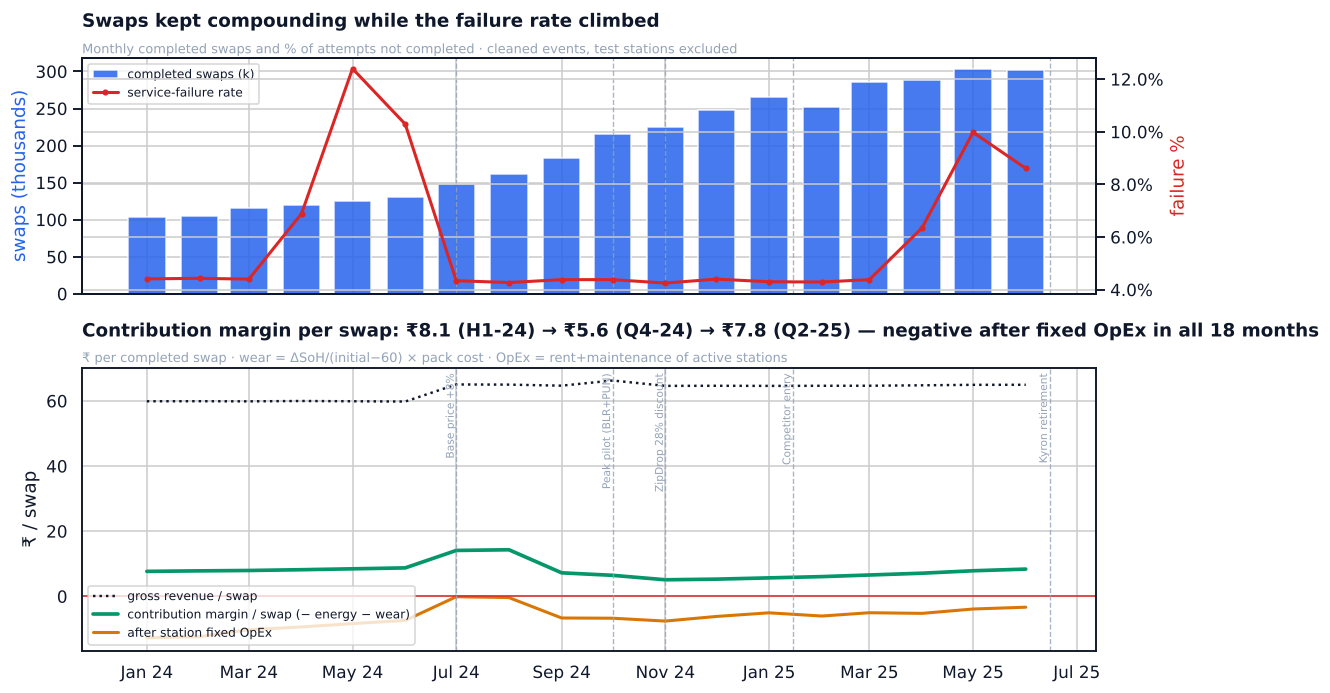

In [15]:
# ── Q1 chart: growth vs margin compression ───────────────────────
fig, axes = plt.subplots(2, 1, figsize=(11,6.4), sharex=True,
                         gridspec_kw={"height_ratios":[1,1.2]})
ax = axes[0]
ax.bar(monthly.m, monthly.completed/1e3, width=22, color=BLUE, alpha=.85, label="completed swaps (k)")
ax2 = ax.twinx()
ax2.plot(monthly.m, monthly.fail_pct, color=RED, lw=2, marker="o", ms=3, label="service-failure rate")
ax2.set_ylabel("failure %", color=RED); ax.set_ylabel("swaps (thousands)", color=BLUE)
ax2.yaxis.set_major_formatter(PercentFormatter())
title2(ax, "Swaps kept compounding while the failure rate climbed",
       "Monthly completed swaps and % of attempts not completed · cleaned events, test stations excluded")
add_milestones(ax, labels=False)
h1,l1 = ax.get_legend_handles_labels(); h2,l2 = ax2.get_legend_handles_labels()
ax.legend(h1+h2, l1+l2, loc="upper left", fontsize=8)

ax = axes[1]
ax.plot(monthly.m, monthly.rev_per_swap, color=NAVY, lw=1.6, ls=":", label="gross revenue / swap")
ax.plot(monthly.m, monthly.cm_per_swap, color=GREEN, lw=2.4, label="contribution margin / swap (− energy − wear)")
ax.plot(monthly.m, monthly.op_per_swap, color=AMBER, lw=2, label="after station fixed OpEx")
ax.axhline(0, color=RED, lw=1)
add_milestones(ax)
title2(ax, f"Contribution margin per swap: ₹{KEY['cm_h1_24']:.1f} (H1-24) → ₹{KEY['cm_q4_24']:.1f} (Q4-24) → ₹{KEY['cm_q2_25']:.1f} (Q2-25) — negative after fixed OpEx in all 18 months",
       "₹ per completed swap · wear = ΔSoH/(initial−60) × pack cost · OpEx = rent+maintenance of active stations")
ax.set_ylabel("₹ / swap"); ax.legend(fontsize=8, loc="lower left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.tight_layout(); savefig(fig,"03_margin_waterfall"); plt.show()

## 3 · Q2 — Failures are a *concentration* problem, not a network problem

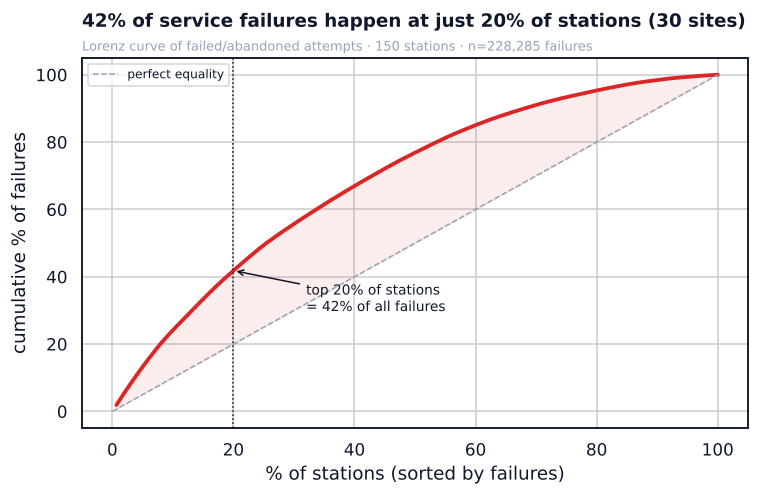

In [16]:
# ── Station Pareto / Lorenz curve of failures ────────────────────
stn_fail = con.execute("""
SELECT station_id, COUNT(*) FILTER (WHERE NOT is_completed) fails,
       COUNT(*) attempts, AVG(queue_wait_sec) avg_wait
FROM swaps_clean GROUP BY 1 ORDER BY fails DESC""").df()
stn_fail["cum_fail_share"] = stn_fail.fails.cumsum()/stn_fail.fails.sum()*100
stn_fail["stn_share"] = (np.arange(len(stn_fail))+1)/len(stn_fail)*100
top20 = stn_fail[stn_fail.stn_share<=20].cum_fail_share.iloc[-1]
top15 = stn_fail[stn_fail.stn_share<=15].cum_fail_share.iloc[-1]
KEY["fail_share_top15pct_stations"] = round(top15,1)
KEY["fail_share_top20pct_stations"] = round(top20,1)
KEY["n_stations"] = len(stn_fail)

fig, ax = plt.subplots(figsize=(7,4.6))
ax.plot(stn_fail.stn_share, stn_fail.cum_fail_share, color=RED, lw=2.5)
ax.plot([0,100],[0,100], color=GREY, ls="--", lw=1, label="perfect equality")
ax.fill_between(stn_fail.stn_share, stn_fail.cum_fail_share,
                stn_fail.stn_share, color=RED, alpha=.08)
ax.axvline(20, color=NAVY, ls=":", lw=1)
ax.annotate(f"top 20% of stations\n= {top20:.0f}% of all failures",
            xy=(20, top20), xytext=(32, top20-12), fontsize=9, color=NAVY,
            arrowprops=dict(arrowstyle="->", color=NAVY))
title2(ax, f"{top20:.0f}% of service failures happen at just 20% of stations ({int(len(stn_fail)*0.2)} sites)",
       f"Lorenz curve of failed/abandoned attempts · {KEY['n_stations']} stations · n={int(stn_fail.fails.sum()):,} failures")
ax.set_xlabel("% of stations (sorted by failures)"); ax.set_ylabel("cumulative % of failures")
ax.legend(fontsize=8); fig.tight_layout(); savefig(fig,"04_lorenz"); plt.show()

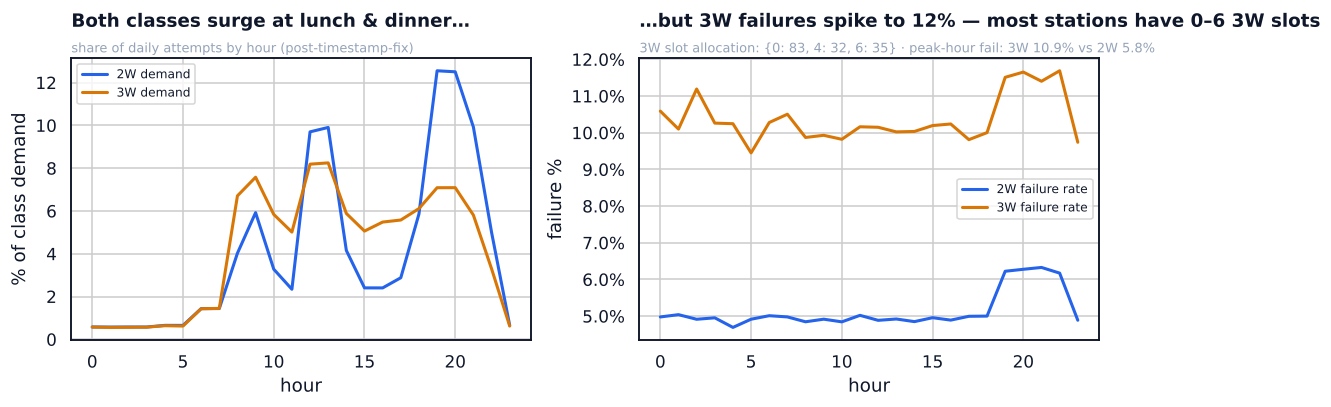

In [17]:
# ── Hour-of-day failure anatomy by vehicle class ─────────────────
hod = con.execute("""
SELECT EXTRACT(hour FROM c.ts)::INT hr, r.vehicle_class,
  COUNT(*) attempts,
  COUNT(*) FILTER (WHERE NOT c.is_completed) fails,
  COUNT(*) FILTER (WHERE c.event_type='failed_no_charged_battery') stockouts
FROM swaps_clean c JOIN riders_c r USING (rider_id)
GROUP BY 1,2 ORDER BY 1,2""").df()
hod["fail_pct"] = 100*hod.fails/hod.attempts
slot3 = con.execute("""SELECT slots_3w, COUNT(*) stations FROM stations_c GROUP BY 1 ORDER BY 1""").df()
KEY["slots_3w_dist"] = slot3.set_index("slots_3w").stations.to_dict()
f3 = hod[hod.vehicle_class=="3W"]; f2 = hod[hod.vehicle_class=="2W"]
KEY["fail_pct_3w_peak"] = round(f3[f3.hr.isin([12,13,19,20,21])].fails.sum()
                               /f3[f3.hr.isin([12,13,19,20,21])].attempts.sum()*100,1)
KEY["fail_pct_2w_peak"] = round(f2[f2.hr.isin([12,13,19,20,21])].fails.sum()
                               /f2[f2.hr.isin([12,13,19,20,21])].attempts.sum()*100,1)

fig, axes = plt.subplots(1,2, figsize=(11,3.8))
ax = axes[0]
for vc, c in [("2W",BLUE),("3W",AMBER)]:
    d = hod[hod.vehicle_class==vc]
    ax.plot(d.hr, d.attempts/d.attempts.sum()*100, color=c, lw=2, label=f"{vc} demand")
ax.set_xlabel("hour"); ax.set_ylabel("% of class demand"); ax.legend(fontsize=8)
title2(ax, "Both classes surge at lunch & dinner…", "share of daily attempts by hour (post-timestamp-fix)")
ax = axes[1]
for vc, c in [("2W",BLUE),("3W",AMBER)]:
    d = hod[hod.vehicle_class==vc]
    ax.plot(d.hr, d.fail_pct, color=c, lw=2, label=f"{vc} failure rate")
ax.set_xlabel("hour"); ax.set_ylabel("failure %"); ax.legend(fontsize=8)
ax.yaxis.set_major_formatter(PercentFormatter())
title2(ax, f"…but 3W failures spike to {f3.fail_pct.max():.0f}% — most stations have 0–6 3W slots",
       f"3W slot allocation: {KEY['slots_3w_dist']} · peak-hour fail: 3W {KEY['fail_pct_3w_peak']}% vs 2W {KEY['fail_pct_2w_peak']}%")
fig.tight_layout(); savefig(fig,"05_hod_class"); plt.show()

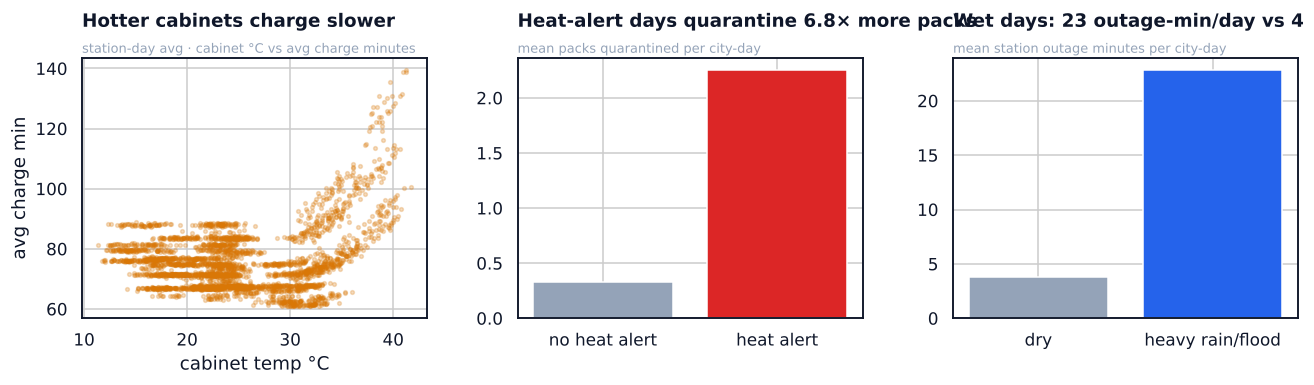

Stockout% dry→wet: [np.float64(3.5), np.float64(2.99)]  · cool→heat-alert: [np.float64(3.12), np.float64(10.32)]


In [18]:
# ── Weather stress: heat slows charging, monsoon kills uptime ────
wx = con.execute("""
SELECT cd.city, cd.date,
  MAX(cd.max_temp_c) max_temp, MAX(cd.rainfall_mm) rain,
  MAX(cd.heat_alert::INT) heat_alert, MAX(cd.flood_disruption::INT) flood,
  MAX(cd.grid_outage_hours) grid_out,
  AVG(h.avg_charge_minutes) chg_min, AVG(h.cabinet_temp_c) cab_temp,
  SUM(h.packs_quarantined) quarantined, SUM(h.outage_minutes) outage_min
FROM city_daily_context_raw cd
JOIN stations_c s ON s.city = cd.city
JOIN hourly_c h ON h.station_id = s.station_id AND h.hour_start::DATE = cd.date
GROUP BY 1,2""").df()

heat = wx.groupby("heat_alert").agg(chg=("chg_min","mean"), q=("quarantined","mean"),
                                    cab=("cab_temp","mean")).round(2)
mons = wx.assign(wet=lambda d:(d.rain>20)|(d.flood>0)).groupby("wet").agg(
        out=("outage_min","mean")).round(1)
daily_fail = con.execute("""
SELECT s.city, c.ts::DATE date,
  COUNT(*) FILTER (WHERE c.event_type='failed_no_charged_battery') stockouts,
  COUNT(*) attempts
FROM swaps_clean c JOIN stations_c s USING(station_id) GROUP BY 1,2""").df()
wxf = wx.merge(daily_fail, on=["city","date"])
wxf["stockout_pct"] = 100*wxf.stockouts/wxf.attempts
g = wxf.assign(wet=lambda d:(d.rain>20)|(d.flood>0),
               hot=lambda d:d.heat_alert>0)
KEY["chg_min_heat"] = [float(heat.chg.get(0,np.nan)), float(heat.chg.get(1,np.nan))]
KEY["quar_heat"]    = [float(heat.q.get(0,np.nan)),  float(heat.q.get(1,np.nan))]
KEY["outage_wet"]   = [float(mons.out.get(False,np.nan)), float(mons.out.get(True,np.nan))]
KEY["stockout_pct_hot"] = [round(g[~g.hot].stockout_pct.mean(),2), round(g[g.hot].stockout_pct.mean(),2)]
KEY["stockout_pct_wet"] = [round(g[~g.wet].stockout_pct.mean(),2), round(g[g.wet].stockout_pct.mean(),2)]

fig, axes = plt.subplots(1,3, figsize=(12,3.6))
sdf = wx.sample(min(4000,len(wx)), random_state=7)
axes[0].scatter(sdf.cab_temp, sdf.chg_min, s=6, alpha=.25, color=AMBER)
title2(axes[0], "Hotter cabinets charge slower", "station-day avg · cabinet °C vs avg charge minutes")
axes[0].set_xlabel("cabinet temp °C"); axes[0].set_ylabel("avg charge min")
axes[1].bar(["no heat alert","heat alert"], KEY["quar_heat"], color=[GREY,RED])
title2(axes[1], f"Heat-alert days quarantine {KEY['quar_heat'][1]/max(KEY['quar_heat'][0],1e-9):.1f}× more packs",
       "mean packs quarantined per city-day")
axes[2].bar(["dry","heavy rain/flood"], KEY["outage_wet"], color=[GREY,BLUE])
title2(axes[2], f"Wet days: {KEY['outage_wet'][1]:.0f} outage-min/day vs {KEY['outage_wet'][0]:.0f}",
       "mean station outage minutes per city-day")
fig.tight_layout(); savefig(fig,"06_weather"); plt.show()
print("Stockout% dry→wet:", KEY["stockout_pct_wet"], " · cool→heat-alert:", KEY["stockout_pct_hot"])

## 4 · Q3 — Equipment generations, expansion waves, competitor entry

In [19]:
# ── Charger generation & expansion wave economics ────────────────
gen = con.execute("""
WITH per_stn AS (
  SELECT c.station_id,
    COUNT(*) FILTER (WHERE c.is_completed) swaps,
    COUNT(*) attempts,
    SUM(c.amount_charged_inr) FILTER (WHERE c.is_completed) rev
  FROM swaps_clean c GROUP BY 1),
chg AS (SELECT station_id, AVG(avg_charge_minutes) chg_min,
               AVG(cabinet_temp_c - ambient_temp_c) temp_delta
        FROM hourly_c GROUP BY 1)
SELECT s.charger_generation gen, COUNT(*) stations,
  ROUND(AVG(p.swaps/DATE_DIFF('day', GREATEST(s.commissioned_date, DATE '2024-01-01'),
        DATE '2025-06-30')),1) swaps_per_stn_day,
  ROUND(100.0*SUM(p.attempts-p.swaps)/SUM(p.attempts),2) fail_pct,
  ROUND(AVG(c.chg_min),1) avg_charge_min,
  ROUND(AVG(c.temp_delta),1) cab_minus_ambient_c,
  ROUND(AVG(s.monthly_rent_inr+s.monthly_maintenance_inr),0) fixed_pm
FROM stations_c s JOIN per_stn p USING(station_id) JOIN chg c USING(station_id)
GROUP BY 1 ORDER BY 1""").df()
print(gen.to_string(index=False))
KEY["gen_table"] = gen.to_dict("records")

wave = con.execute("""
WITH per_stn AS (
  SELECT c.station_id,
    COUNT(*) FILTER (WHERE c.is_completed) swaps,
    COUNT(*) attempts,
    SUM(c.amount_charged_inr) FILTER (WHERE c.is_completed) rev
  FROM swaps_clean c GROUP BY 1)
SELECT s.expansion_wave, s.location_type, COUNT(*) n,
  ROUND(AVG(p.swaps/GREATEST(DATE_DIFF('day',
      GREATEST(s.commissioned_date, DATE '2024-01-01'), DATE '2025-06-30'),1)),1) spd,
  ROUND(AVG(p.rev/GREATEST(DATE_DIFF('day',
      GREATEST(s.commissioned_date, DATE '2024-01-01'), DATE '2025-06-30'),1)
      /((s.monthly_rent_inr+s.monthly_maintenance_inr)/30.44)),2) rev_to_fixed
FROM stations_c s JOIN per_stn p USING(station_id)
GROUP BY 1,2 ORDER BY 1,2""").df()
piv = wave.pivot_table(index="location_type", columns="expansion_wave", values="spd")
cnt = wave.pivot_table(index="location_type", columns="expansion_wave", values="n", aggfunc="sum")
print("\nSwaps/station/day:\n", piv.round(1).to_string())
print("\nStation counts:\n", cnt.fillna(0).astype(int).to_string())
print("\nRevenue ÷ fixed cost (daily):\n",
      wave.pivot_table(index="location_type", columns="expansion_wave",
                       values="rev_to_fixed").round(2).to_string())
KEY["wave_spd"] = {f"{r.expansion_wave}|{r.location_type}": r.spd for r in wave.itertuples()}
KEY["wave_rev_to_fixed"] = {f"{r.expansion_wave}|{r.location_type}": r.rev_to_fixed
                            for r in wave.itertuples()}
KEY["wave_counts"] = {f"{r.expansion_wave}|{r.location_type}": int(r.n) for r in wave.itertuples()}

 gen  stations  swaps_per_stn_day  fail_pct  avg_charge_min  cab_minus_ambient_c  fixed_pm
Gen1        51               60.6      7.24            91.8                  6.6   22968.0
Gen2        62               55.4      4.85            64.3                  6.6   24256.0
Gen3        37               70.6      4.85            42.2                  6.6   23894.0

Swaps/station/day:
 expansion_wave     Launch  Wave1_2024H2  Wave2_2025H1
location_type                                        
commercial_hub       63.8         131.4          87.8
highway_fuel_pump    43.4          55.0          87.8
market               59.2           NaN          77.5
residential          48.4          51.4          46.9
tech_park            41.3          68.1          69.9
transit_hub          47.7          50.5          37.2

Station counts:
 expansion_wave     Launch  Wave1_2024H2  Wave2_2025H1
location_type                                        
commercial_hub         39             1             4
hig

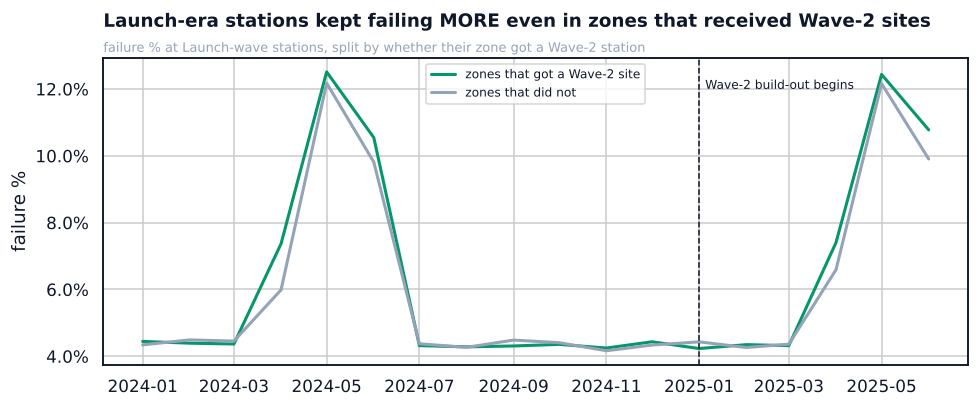

In [20]:
# ── Did the waves relieve congestion where it exists? ────────────
relief = con.execute("""
WITH launch_load AS (
  SELECT s.zone, DATE_TRUNC('month', c.ts)::DATE m,
    COUNT(*) FILTER (WHERE NOT c.is_completed) fails, COUNT(*) attempts
  FROM swaps_clean c JOIN stations_c s USING(station_id)
  WHERE s.expansion_wave='Launch' GROUP BY 1,2),
wave2_zones AS (SELECT DISTINCT zone FROM stations_c WHERE expansion_wave='Wave2_2025H1')
SELECT ll.m,
  CASE WHEN wz.zone IS NOT NULL THEN 'zones that got a Wave-2 site'
       ELSE 'zones that did not' END grp,
  SUM(ll.fails)*100.0/SUM(ll.attempts) fail_pct
FROM launch_load ll LEFT JOIN wave2_zones wz USING(zone)
GROUP BY 1,2 ORDER BY 1""").df()
relief["m"]=pd.to_datetime(relief.m)
fig, ax = plt.subplots(figsize=(9,3.8))
for g_, c in [("zones that got a Wave-2 site",GREEN),("zones that did not",GREY)]:
    d = relief[relief.grp==g_]
    ax.plot(d.m, d.fail_pct, color=c, lw=2, label=g_)
ax.axvline(pd.Timestamp("2025-01-01"), color=NAVY, ls="--", lw=1)
ax.text(pd.Timestamp("2025-01-05"), ax.get_ylim()[1]*0.95, "Wave-2 build-out begins",
        fontsize=8, color=NAVY, va="top")
title2(ax, "Launch-era stations kept failing MORE even in zones that received Wave-2 sites",
       "failure % at Launch-wave stations, split by whether their zone got a Wave-2 station")
ax.set_ylabel("failure %"); ax.yaxis.set_major_formatter(PercentFormatter())
ax.legend(fontsize=8); fig.tight_layout(); savefig(fig,"07_wave_relief"); plt.show()

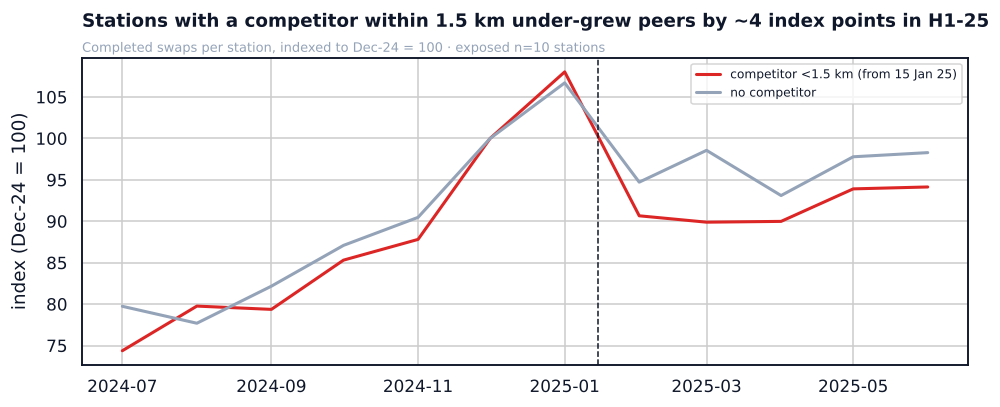

In [21]:
# ── Competitor entry 2025-01-15: exposed vs not ──────────────────
comp = con.execute("""
SELECT DATE_TRUNC('month', c.ts)::DATE m,
  CASE WHEN s.competitor_within_1_5km_since IS NOT NULL
       THEN 'competitor <1.5 km (from 15 Jan 25)' ELSE 'no competitor' END grp,
  COUNT(*) FILTER (WHERE c.is_completed) swaps,
  COUNT(DISTINCT c.station_id) stns
FROM swaps_clean c JOIN stations_c s USING(station_id)
WHERE c.ts >= DATE '2024-07-01' GROUP BY 1,2 ORDER BY 1""").df()
comp["m"]=pd.to_datetime(comp.m); comp["sps"]=comp.swaps/comp.stns
base = comp[comp.m=="2024-12-01"].set_index("grp").sps
comp["idx"] = comp.apply(lambda r: 100*r.sps/base[r.grp], axis=1)
n_exposed = con.execute("""SELECT COUNT(*) FROM stations_c
                           WHERE competitor_within_1_5km_since IS NOT NULL""").fetchone()[0]
KEY["n_competitor_exposed"] = n_exposed
post = comp[comp.m>="2025-01-01"].groupby("grp").idx.mean()
KEY["competitor_idx_post"] = post.round(1).to_dict()

fig, ax = plt.subplots(figsize=(9,3.8))
for g_, c in [("competitor <1.5 km (from 15 Jan 25)",RED),("no competitor",GREY)]:
    d = comp[comp.grp==g_]
    ax.plot(d.m, d.idx, lw=2, color=c, label=f"{g_}")
ax.axvline(pd.Timestamp("2025-01-15"), color=NAVY, ls="--", lw=1)
gap = post["no competitor"] - post["competitor <1.5 km (from 15 Jan 25)"]
title2(ax, f"Stations with a competitor within 1.5 km under-grew peers by ~{gap:.0f} index points in H1-25",
       f"Completed swaps per station, indexed to Dec-24 = 100 · exposed n={n_exposed} stations")
ax.set_ylabel("index (Dec-24 = 100)"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig,"08_competitor"); plt.show()

## 5 · Q4 — The Kyron battery failure and what low SoH does to riders

Excluded pre-commission SoH readings: 983,481
manufacturing_lot pack_type  packs  soh_now      capex
          KY-2407 2W_2.1kWh    452     60.5 14459776.0
          KY-2407 3W_4.8kWh     24     68.4  1628001.0
          KY-2408 2W_2.1kWh    471     60.5 15067146.0
          KY-2408 3W_4.8kWh     18     68.4  1215660.0
          KY-2409 2W_2.1kWh    462     60.6 14767711.0
          KY-2409 3W_4.8kWh     11     68.5   758724.0


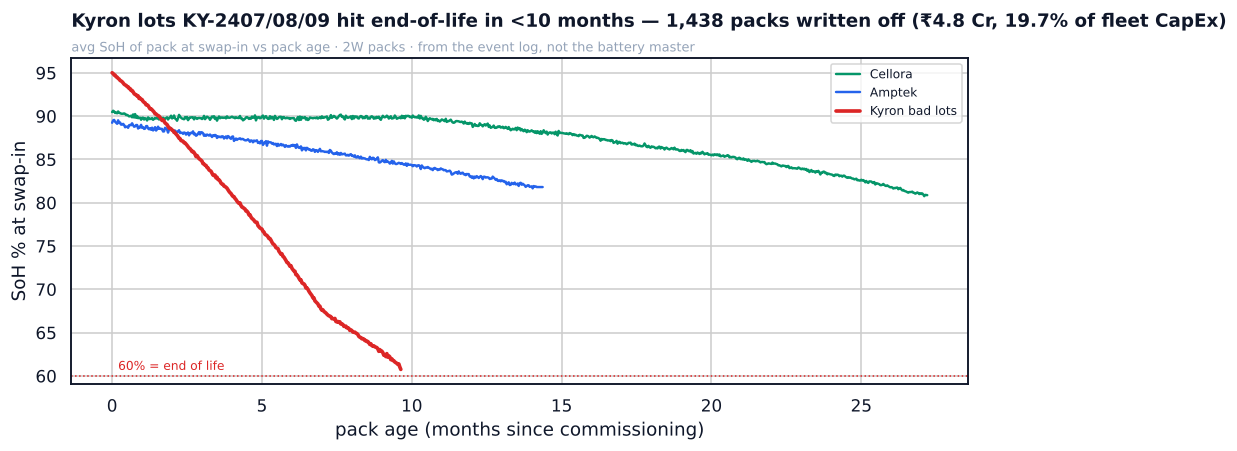

In [22]:
# ── Supplier/lot degradation from the swap log itself ────────────
# Data-quality note (10th hygiene observation): 1.00M completed swaps (27.5%)
# reference a pack BEFORE its recorded commission_date (826k even precede
# manufacture_date) — the battery master's dates are unreliable for 5,144 of
# 6,500 packs. Age-based analysis therefore uses post-commission readings only;
# the Kyron lots' own master dates are internally consistent (commissioned
# Sep-10-24, retired Jun-15-25 → <10 months to end-of-life).
pre = con.execute("""SELECT COUNT(*) FROM swaps_clean c
  JOIN batteries_raw b ON b.battery_id=c.battery_in_id
  WHERE c.is_completed AND c.ts::DATE < b.commission_date""").fetchone()[0]
print(f"Excluded pre-commission SoH readings: {pre:,}")
KEY["pre_commission_readings"] = pre

decay = con.execute("""
SELECT b.supplier,
  CASE WHEN b.manufacturing_lot IN ('KY-2407','KY-2408','KY-2409')
       THEN 'Kyron bad lots' ELSE b.supplier END cohort,
  DATE_DIFF('day', b.commission_date, c.ts)/30 age_months,
  AVG(c.soh_in_pct) soh, COUNT(*) n
FROM swaps_clean c
JOIN batteries_raw b ON b.battery_id = c.battery_in_id
WHERE c.is_completed AND b.pack_type='2W_2.1kWh'
  AND c.ts::DATE >= b.commission_date
GROUP BY 1,2,3 HAVING COUNT(*) > 200 ORDER BY 2,3""").df()

retired = con.execute("""
SELECT manufacturing_lot, pack_type, COUNT(*) packs,
  ROUND(AVG(current_soh_pct),1) soh_now, SUM(purchase_cost_inr) capex
FROM batteries_raw
WHERE retired_date = DATE '2025-06-15' GROUP BY 1,2 ORDER BY 1,2""").df()
print(retired.to_string(index=False))
writeoff = float(retired.capex.sum()); n_ret = int(retired.packs.sum())
KEY["kyron_writeoff_inr"] = writeoff
KEY["kyron_packs_retired"] = n_ret
KEY["kyron_retired_detail"] = retired.to_dict("records")
fleet_capex = con.execute("SELECT SUM(purchase_cost_inr) FROM batteries_raw").fetchone()[0]
KEY["kyron_writeoff_pct_fleet"] = round(100*writeoff/fleet_capex,1)

fig, ax = plt.subplots(figsize=(9,4.2))
for coh, c in [("Cellora",GREEN),("Amptek",BLUE),("Kyron",AMBER),("Kyron bad lots",RED)]:
    d = decay[decay.cohort==coh].groupby("age_months").soh.mean()
    if len(d): ax.plot(d.index, d.values, lw=2.4 if "bad" in coh else 1.6,
                       color=c, label=coh)
ax.axhline(60, color=RED, ls=":", lw=1); ax.text(0.2, 60.7, "60% = end of life", fontsize=8, color=RED)
title2(ax, f"Kyron lots KY-2407/08/09 hit end-of-life in <10 months — {n_ret:,} packs written off (₹{writeoff/1e7:.1f} Cr, {KEY['kyron_writeoff_pct_fleet']}% of fleet CapEx)",
       "avg SoH of pack at swap-in vs pack age · 2W packs · from the event log, not the battery master")
ax.set_xlabel("pack age (months since commissioning)"); ax.set_ylabel("SoH % at swap-in")
ax.legend(fontsize=8); fig.tight_layout(); savefig(fig,"09_kyron"); plt.show()

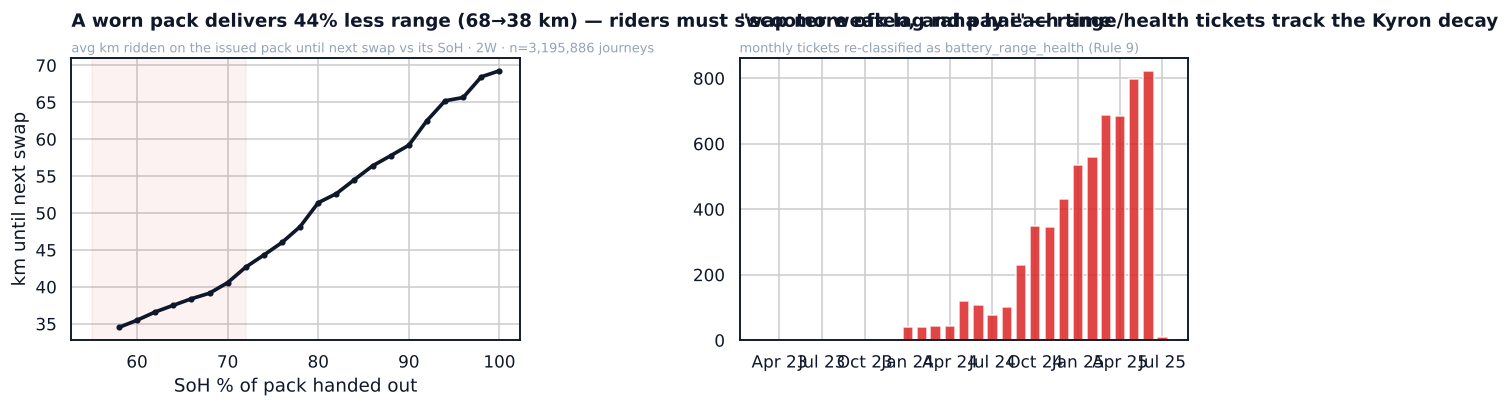

In [23]:
# ── Delivered range vs SoH of the issued pack ────────────────────
rng = con.execute("""
SELECT ROUND(c.soh_in_pct/2)*2 soh_bucket, AVG(c.km_clean) km, COUNT(*) n
FROM swaps_clean c
JOIN batteries_raw b ON b.battery_id = c.battery_in_id
WHERE c.is_completed AND c.km_clean IS NOT NULL AND b.pack_type='2W_2.1kWh'
  AND c.soh_in_pct BETWEEN 55 AND 100
GROUP BY 1 HAVING COUNT(*) > 500 ORDER BY 1""").df()
km_hi = rng[rng.soh_bucket>=95].km.mean(); km_lo = rng[rng.soh_bucket<=72].km.mean()
KEY["range_km_soh95"] = round(km_hi,1); KEY["range_km_soh72"] = round(km_lo,1)
KEY["range_loss_pct"] = round(100*(km_hi-km_lo)/km_hi,1)

tick_rng = con.execute("""
SELECT DATE_TRUNC('month', created_ts)::DATE m,
  COUNT(*) FILTER (WHERE true_category='battery_range_health') range_tk
FROM tickets_t GROUP BY 1 ORDER BY 1""").df()

fig, axes = plt.subplots(1,2, figsize=(11,3.8))
ax=axes[0]
ax.plot(rng.soh_bucket, rng.km, color=NAVY, lw=2.4, marker="o", ms=3)
ax.axvspan(55,72,color=RED,alpha=.06)
title2(ax, f"A worn pack delivers {KEY['range_loss_pct']:.0f}% less range ({km_hi:.0f}→{km_lo:.0f} km) — riders must swap more often, and pay each time",
       f"avg km ridden on the issued pack until next swap vs its SoH · 2W · n={int(rng.n.sum()):,} journeys")
ax.set_xlabel("SoH % of pack handed out"); ax.set_ylabel("km until next swap")
ax=axes[1]
tick_rng["m"]=pd.to_datetime(tick_rng.m)
ax.bar(tick_rng.m, tick_rng.range_tk, width=22, color=RED, alpha=.85)
title2(ax, '"scooter weak lag raha hai" — range/health tickets track the Kyron decay',
       "monthly tickets re-classified as battery_range_health (Rule 9)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.tight_layout(); savefig(fig,"10_range"); plt.show()

## 6 · Q5 — Pricing: base hike, the 2-city peak pilot, partner economics

In [24]:
# ── Base price change (detected, not assumed) ────────────────────
pr = con.execute("""
SELECT ts::DATE d, list_price_inr, COUNT(*) n
FROM swaps_clean WHERE tariff_code='STD' AND is_completed
  AND ts BETWEEN DATE '2024-06-24' AND DATE '2024-07-08'
GROUP BY 1,2 ORDER BY 1,2""").df()
print(pr.pivot_table(index="d",columns="list_price_inr",values="n").fillna(0).astype(int).to_string())
# → clean flip 60→65 (2W) and 100→110 (3W) on 2024-07-01: +8.3% / +10%
KEY["price_change_date"] = "2024-07-01"

paygrow = con.execute("""
SELECT DATE_TRUNC('month', c.ts)::DATE m, r.plan_type,
  COUNT(*) FILTER (WHERE c.is_completed) swaps,
  COUNT(DISTINCT c.rider_id) riders
FROM swaps_clean c JOIN riders_c r USING(rider_id)
WHERE c.ts BETWEEN DATE '2024-04-01' AND DATE '2024-09-30'
GROUP BY 1,2 ORDER BY 1""").df()
paygrow["m"] = pd.to_datetime(paygrow.m)
paygrow["spr"] = paygrow.swaps/paygrow.riders
pre  = paygrow[paygrow.m <  "2024-07-01"].groupby("plan_type").spr.mean()
post = paygrow[paygrow.m >= "2024-07-01"].groupby("plan_type").spr.mean()
chg = ((post-pre)/pre*100).round(1)
print("\nSwaps per active rider, 3m pre vs post hike (% change):\n", chg.to_string())
KEY["price_hike_spr_change_pct"] = chg.to_dict()

list_price_inr  60.0   65.0   100.0  110.0
d                                         
2024-06-24       1420      0     78      0
2024-06-25       1385      0     80      0
2024-06-26       1399      0     76      0
2024-06-27       1472      0     81      0
2024-06-28       1498      0     79      0
2024-06-29       1467      0     86      0
2024-06-30       1489      0     84      0
2024-07-01          0   1482      0     79
2024-07-02          0   1482      0     85
2024-07-03          0   1518      0     94
2024-07-04          0   1562      0     91
2024-07-05          0   1519      0     87
2024-07-06          0   1500      0     91
2024-07-07          0   1539      0     87

Swaps per active rider, 3m pre vs post hike (% change):
 plan_type
partner_billed    5.1
pay_as_you_go     6.7
prepaid_pack      6.1


In [25]:
# ── Peak pilot DiD: Bengaluru+Pune vs 4 control cities ───────────
# Stable panel: only stations live before the pilot and never decommissioned,
# otherwise Wave-1 openings (mostly in control cities) contaminate per-station trends.
did = con.execute("""
SELECT s.city, DATE_TRUNC('month', c.ts)::DATE m,
  COUNT(*) FILTER (WHERE c.is_completed) swaps,
  COUNT(DISTINCT c.station_id) stns,
  COUNT(*) FILTER (WHERE c.is_completed AND
    EXTRACT(hour FROM c.ts) IN (12,13,19,20,21)) peak_swaps
FROM swaps_clean c JOIN stations_c s USING(station_id)
WHERE c.ts BETWEEN DATE '2024-04-01' AND DATE '2025-03-31'
  AND s.commissioned_date <= DATE '2024-06-30'
  AND s.decommissioned_date IS NULL
GROUP BY 1,2""").df()
did["pilot"] = did.city.isin(["Bengaluru","Pune"])
did["sps"] = did.swaps/did.stns
did["peak_share"] = 100*did.peak_swaps/did.swaps
did["m"] = pd.to_datetime(did.m)
PRE  = (did.m >= "2024-07-01") & (did.m <= "2024-09-30")
POST = (did.m >= "2024-10-01") & (did.m <= "2024-12-31")

# Confound check: did new-station openings dilute pilot and control differently?
mix = con.execute("""SELECT expansion_wave,
  COUNT(*) FILTER (WHERE city IN ('Bengaluru','Pune')) pilot,
  COUNT(*) FILTER (WHERE city NOT IN ('Bengaluru','Pune')) control
FROM stations_c GROUP BY 1 ORDER BY 1""").df()
print("Station mix (pilot vs control):\n", mix.to_string(index=False))
print("→ Wave-1 added 33% to the pre-existing base in BOTH groups (11/33 vs 19/57):"
      "\n  cannibalisation is symmetric, so it does not explain a pilot-vs-control gap.\n")

def cell(mask, col):
    d = did[mask]; return d.groupby("pilot")[col].mean()

tbl = pd.DataFrame({
    "pre (Jul–Sep 24)":  cell(PRE,"sps"), "post (Oct–Dec 24)": cell(POST,"sps")})
tbl.index = tbl.index.map({False:"control (4 cities)",True:"pilot (BLR+PUN)"})
tbl["Δ"] = tbl.iloc[:,1]-tbl.iloc[:,0]
did_sps = tbl.loc["pilot (BLR+PUN)","Δ"] - tbl.loc["control (4 cities)","Δ"]
print("Swaps per station per month:\n", tbl.round(1).to_string())
print(f"\nDiD estimate (volume): {did_sps:+.1f} swaps/station/month")

tbl2 = pd.DataFrame({
    "pre":  cell(PRE,"peak_share"), "post": cell(POST,"peak_share")})
tbl2.index = tbl.index
tbl2["Δ"] = tbl2.post-tbl2.pre
did_peak = tbl2.loc["pilot (BLR+PUN)","Δ"] - tbl2.loc["control (4 cities)","Δ"]
print("\nPeak-hour share of swaps (%):\n", tbl2.round(2).to_string())
print(f"DiD estimate (peak share): {did_peak:+.2f} pp")
KEY["did_volume_sps"] = round(float(did_sps),1)
KEY["did_peak_share_pp"] = round(float(did_peak),2)

# Who actually responded: payg riders vs surcharge-exempt B2B
seg = con.execute("""
SELECT r.plan_type,
  100.0*COUNT(*) FILTER (WHERE EXTRACT(hour FROM c.ts) IN (12,13,19,20,21))/COUNT(*) peak_share,
  COUNT(*) n
FROM swaps_clean c
JOIN riders_c r USING(rider_id) JOIN stations_c s USING(station_id)
WHERE c.is_completed AND s.city IN ('Bengaluru','Pune')
  AND c.ts >= DATE '2024-10-01' GROUP BY 1""").df()
print("\nPeak share in pilot cities post-launch by plan:\n", seg.round(2).to_string(index=False))

exempt = con.execute("""
SELECT fp.peak_surcharge_billable,
  100.0*COUNT(*) FILTER (WHERE EXTRACT(hour FROM c.ts) IN (12,13,19,20,21))/COUNT(*) peak_share,
  COUNT(*) FILTER (WHERE EXTRACT(hour FROM c.ts) IN (12,13,19,20,21)) peak_swaps
FROM swaps_clean c
JOIN riders_c r USING(rider_id)
JOIN fleet_partners_raw fp USING(partner_id)
JOIN stations_c s USING(station_id)
WHERE c.is_completed AND s.city IN ('Bengaluru','Pune') AND c.ts >= DATE '2024-10-01'
GROUP BY 1""").df()
print("\nPartner peak share by surcharge billability (pilot, post):\n",
      exempt.round(2).to_string(index=False))
ex_swaps = int(exempt[exempt.peak_surcharge_billable=='N'].peak_swaps.iloc[0])
KEY["exempt_peak_swaps_pilot"] = ex_swaps
KEY["exempt_leakage_inr"] = ex_swaps*15
KEY["peak_share_by_billable"] = exempt.set_index("peak_surcharge_billable").peak_share.round(2).to_dict()

disp = con.execute("""
SELECT CASE WHEN s.city IN ('Bengaluru','Pune') THEN 'pilot' ELSE 'control' END grp,
  CASE WHEN t.created_ts >= DATE '2024-10-01' THEN 'post' ELSE 'pre' END per,
  COUNT(*) FILTER (WHERE t.true_category='billing_dispute') disputes, COUNT(*) tk
FROM tickets_t t JOIN stations_c s USING(station_id)
WHERE t.created_ts BETWEEN DATE '2024-04-01' AND DATE '2025-03-31'
GROUP BY 1,2""").df()
disp["rate"] = 100*disp.disputes/disp.tk
dd = disp.pivot_table(index="grp",columns="per",values="rate")
did_disp = (dd.loc['pilot','post']-dd.loc['pilot','pre'])-(dd.loc['control','post']-dd.loc['control','pre'])
print(f"\nBilling-dispute share of tickets (DiD): {did_disp:+.2f} pp")
KEY["did_billing_disputes_pp"] = round(float(did_disp),2)

Station mix (pilot vs control):
 expansion_wave  pilot  control
        Launch     33       57
  Wave1_2024H2     11       19
  Wave2_2025H1     10       20
→ Wave-1 added 33% to the pre-existing base in BOTH groups (11/33 vs 19/57):
  cannibalisation is symmetric, so it does not explain a pilot-vs-control gap.

Swaps per station per month:
                     pre (Jul–Sep 24)  post (Oct–Dec 24)      Δ
pilot                                                         
control (4 cities)            1735.2             2136.2  401.1
pilot (BLR+PUN)               1786.4             1866.5   80.2

DiD estimate (volume): -320.9 swaps/station/month

Peak-hour share of swaps (%):
                       pre   post     Δ
pilot                                 
control (4 cities)  52.48  53.00  0.53
pilot (BLR+PUN)     53.89  51.94 -1.95
DiD estimate (peak share): -2.48 pp

Peak share in pilot cities post-launch by plan:
      plan_type  peak_share      n
 pay_as_you_go       57.46 188778
partner_bil


Billing-dispute share of tickets (DiD): -3.23 pp


partner_id partner_name  swaps         rev  cm_per_swap  cm_after_wc  peak_share  payment_terms_days peak_surcharge_billable
     FP-01     FeastFly 515420 31969689.50         8.56         7.95       61.92                  30                       Y
     FP-03      ZipDrop 547921 28532505.20        -2.49        -3.26       59.83                  45                       N
     FP-02   ParcelNest 295913 16723913.75         2.97         2.41       18.61                  30                       Y
     FP-05   Swiggle Go 237217 14068470.10         5.67         5.08       62.41                  30                       N
     FP-04     CargoTuk 131231 13052304.80        -5.54        -6.52       15.68                  30                       Y
     FP-07    QuickCart 127678  7916923.95         9.58         8.96       59.63                  30                       Y
     FP-06    RideMitra 119277  7480736.20         9.64         9.33       24.36                  15                       Y



ZipDrop before/after amendment:
                             per  swaps  rev_per_swap  disc_per_swap  realized_disc_pct  energy_per_swap  wear_per_swap    cm
1_before Nov-24 (contract: 12%) 212518         57.49           7.84               12.0            20.70          31.07  5.72
 2_after Nov-24 (contract: 28%) 335403         48.65          18.92               28.0            18.16          38.18 -7.70


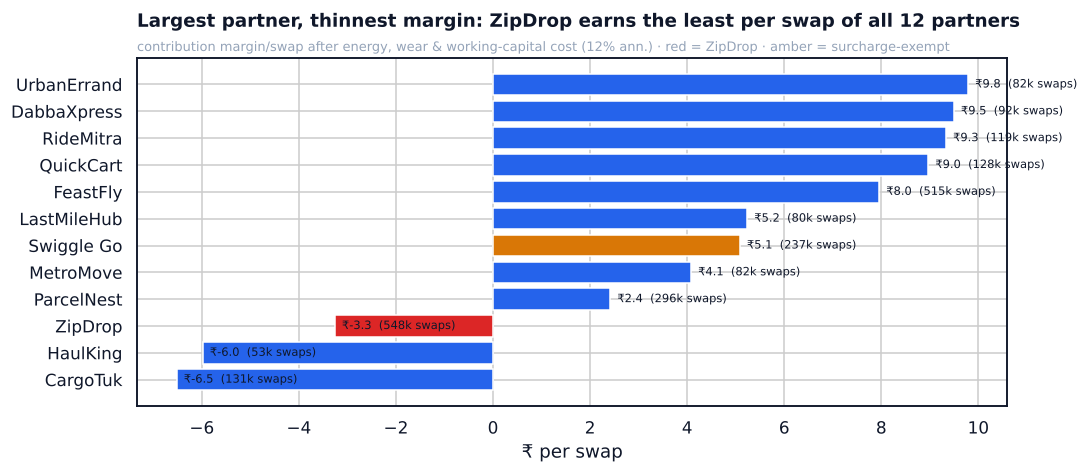

In [26]:
# ── Fleet partner unit economics (all 12) ────────────────────────
part = con.execute("""
WITH pe AS (
  SELECT r.partner_id, COUNT(*) FILTER (WHERE c.is_completed) swaps,
    SUM(c.amount_charged_inr) FILTER (WHERE c.is_completed) rev,
    SUM(c.list_price_inr - c.amount_charged_inr) FILTER (WHERE c.is_completed) disc,
    SUM(c.energy_to_recharge_kwh*s.grid_tariff_inr_kwh) FILTER (WHERE c.is_completed) energy,
    SUM(w.wear_inr) wear,
    100.0*COUNT(*) FILTER (WHERE c.is_completed AND
        EXTRACT(hour FROM c.ts) IN (12,13,19,20,21))/COUNT(*) peak_share
  FROM swaps_clean c
  JOIN riders_c r USING(rider_id)
  JOIN stations_c s USING(station_id)
  LEFT JOIN swap_wear w USING(event_id)
  WHERE r.partner_id IS NOT NULL GROUP BY 1)
SELECT fp.partner_id, fp.partner_name, fp.partner_segment, fp.contract_type,
  fp.payment_terms_days, fp.peak_surcharge_billable,
  pe.swaps, pe.rev, pe.disc, pe.energy, pe.wear, pe.peak_share,
  (pe.rev - pe.energy - pe.wear) / pe.swaps AS cm_per_swap,
  pe.rev * fp.payment_terms_days/365.0 * 0.12 AS wc_cost
FROM pe JOIN fleet_partners_raw fp USING(partner_id) ORDER BY pe.rev DESC""").df()
part["cm_after_wc"] = (part.rev - part.energy - part.wear - part.wc_cost)/part.swaps
print(part[["partner_id","partner_name","swaps","rev","cm_per_swap","cm_after_wc",
            "peak_share","payment_terms_days","peak_surcharge_billable"]]
      .round(2).to_string(index=False))
KEY["partner_table"] = part[["partner_id","partner_name","swaps","rev","cm_per_swap",
    "cm_after_wc","peak_share","peak_surcharge_billable","payment_terms_days"]]\
    .round(2).to_dict("records")

zd = con.execute("""
SELECT CASE WHEN c.ts < DATE '2024-11-01' THEN '1_before Nov-24 (contract: 12%)'
            ELSE '2_after Nov-24 (contract: 28%)' END per,
  COUNT(*) FILTER (WHERE c.is_completed) swaps,
  AVG(c.amount_charged_inr) FILTER (WHERE c.is_completed) rev_per_swap,
  AVG(c.discount_inr)       FILTER (WHERE c.is_completed) disc_per_swap,
  AVG(c.discount_inr / NULLIF(c.list_price_inr,0))
    FILTER (WHERE c.is_completed) * 100 AS realized_disc_pct,
  SUM(c.energy_to_recharge_kwh*s.grid_tariff_inr_kwh) FILTER (WHERE c.is_completed)
    / COUNT(*) FILTER (WHERE c.is_completed) energy_per_swap,
  SUM(w.wear_inr)/COUNT(*) FILTER (WHERE c.is_completed) wear_per_swap
FROM swaps_clean c
JOIN riders_c r USING(rider_id) JOIN stations_c s USING(station_id)
LEFT JOIN swap_wear w USING(event_id)
WHERE r.partner_id='FP-03' GROUP BY 1 ORDER BY 1""").df()
zd["cm"] = zd.rev_per_swap - zd.energy_per_swap - zd.wear_per_swap
print("\nZipDrop before/after amendment:\n", zd.round(2).to_string(index=False))
KEY["zipdrop_cm_before"] = round(float(zd.cm.iloc[0]),2)
KEY["zipdrop_cm_after"]  = round(float(zd.cm.iloc[1]),2)
KEY["zipdrop_disc_pct_before"] = round(float(zd.realized_disc_pct.iloc[0]),1)
KEY["zipdrop_disc_pct_after"]  = round(float(zd.realized_disc_pct.iloc[1]),1)
KEY["zipdrop_monthly_swaps_after"] = int(zd.swaps.iloc[1]/8)  # Nov24–Jun25 = 8 months
# If realized_disc_pct does NOT jump to ~28%, the signed amendment is not being
# applied in billing — that is a contract-vs-invoicing gap worth flagging on its own.

fig, ax = plt.subplots(figsize=(10,4.4))
ps = part.sort_values("cm_after_wc")
cols = [RED if p=="FP-03" else (AMBER if b=="N" else BLUE)
        for p,b in zip(ps.partner_id, ps.peak_surcharge_billable)]
ax.barh(ps.partner_name, ps.cm_after_wc, color=cols)
for i,(v,s_) in enumerate(zip(ps.cm_after_wc, ps.swaps)):
    ax.text(v+0.15, i, f"₹{v:.1f}  ({s_/1e3:.0f}k swaps)", va="center", fontsize=7.5, color=NAVY)
title2(ax, "Largest partner, thinnest margin: ZipDrop earns the least per swap of all 12 partners",
       "contribution margin/swap after energy, wear & working-capital cost (12% ann.) · red = ZipDrop · amber = surcharge-exempt")
ax.set_xlabel("₹ per swap"); fig.tight_layout(); savefig(fig,"11_partners"); plt.show()

## 7 · Q6 — Why new riders leave: first-14-day experience
*Causal caution:* these are observational associations with exposure controls, not a randomized
experiment. Odds ratios adjust for activity volume so "churned riders saw fewer failures because
they rode less" doesn't contaminate the comparison.

    cohort  riders  d14  d30  d60
2024-01-01     601 91.7 85.2 80.5
2024-02-01     567 93.1 85.0 80.2
2024-03-01     601 92.7 87.5 80.4
2024-04-01     663 92.6 82.4 77.7
2024-05-01     722 89.1 79.1 73.0
2024-06-01     716 91.2 83.4 79.1
2024-07-01     811 93.8 88.2 80.9
2024-08-01     856 92.9 86.8 82.1
2024-09-01     869 92.9 86.1 80.8
2024-10-01    1204 92.1 85.4 81.2
2024-11-01    1015 94.4 86.5 81.7
2024-12-01    1061 94.0 86.7 82.2
2025-01-01    1079 93.0 87.5 83.0
2025-02-01    1036 93.9 86.4 80.1
2025-03-01     939 92.7 84.6 78.2
2025-04-01    1120 92.1 81.5  NaN
2025-05-01    1309 90.5  NaN  NaN
2025-06-01    1231  NaN  NaN  NaN


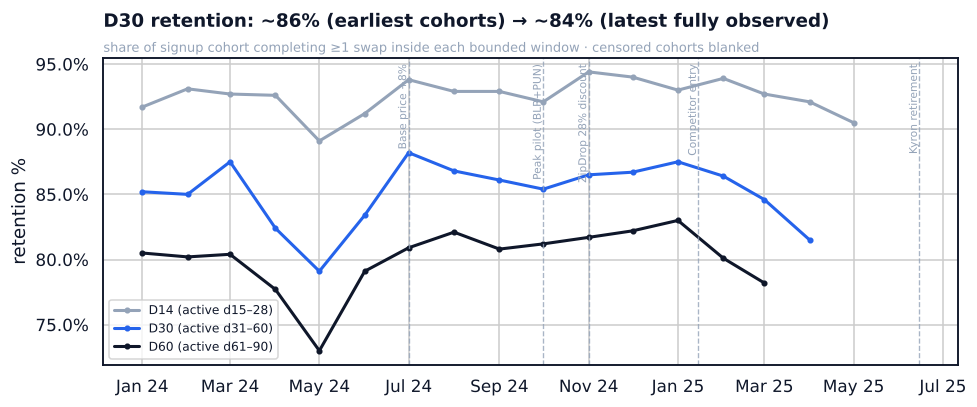

In [27]:
# ── Cohort retention D14/D30/D60 with right-censoring ────────────
# Bounded activity windows (D14: active days 15–28, D30: 31–60, D60: 61–90).
# 'Ever swapped after day N' saturates to 100% for old cohorts (they had 17
# months to qualify), so bounded windows are the only cohort-fair definition.
# Cohorts without a fully observed window are blanked (right-censoring).
ret = con.execute("""
WITH f AS (
  SELECT r.rider_id, r.signup_date,
    COUNT(*) FILTER (WHERE c.is_completed AND c.ts::DATE
      BETWEEN r.signup_date + 15 AND r.signup_date + 28) w14,
    COUNT(*) FILTER (WHERE c.is_completed AND c.ts::DATE
      BETWEEN r.signup_date + 31 AND r.signup_date + 60) w30,
    COUNT(*) FILTER (WHERE c.is_completed AND c.ts::DATE
      BETWEEN r.signup_date + 61 AND r.signup_date + 90) w60
  FROM riders_c r LEFT JOIN swaps_clean c USING(rider_id)
  WHERE r.signup_date >= DATE '2024-01-01'   -- 3,600 riders pre-date the event log: left-censored, excluded
  GROUP BY 1,2)
SELECT DATE_TRUNC('month', signup_date)::DATE cohort, COUNT(*) riders,
  CASE WHEN DATE '2025-06-30' - MAX(signup_date) >= 28
    THEN ROUND(100.0*COUNT(*) FILTER (WHERE w14>0)/COUNT(*),1) END d14,
  CASE WHEN DATE '2025-06-30' - MAX(signup_date) >= 60
    THEN ROUND(100.0*COUNT(*) FILTER (WHERE w30>0)/COUNT(*),1) END d30,
  CASE WHEN DATE '2025-06-30' - MAX(signup_date) >= 90
    THEN ROUND(100.0*COUNT(*) FILTER (WHERE w60>0)/COUNT(*),1) END d60
FROM f GROUP BY 1 ORDER BY 1""").df()
ret["cohort"]=pd.to_datetime(ret.cohort)
print(ret.to_string(index=False))
d30v = ret.dropna(subset=["d30"])
KEY["d30_first3"] = round(d30v.d30.iloc[:3].mean(),1)
KEY["d30_last3"]  = round(d30v.d30.iloc[-3:].mean(),1)
fig, ax = plt.subplots(figsize=(9,3.8))
for col,c,l in [("d14",GREY,"D14 (active d15–28)"),("d30",BLUE,"D30 (active d31–60)"),
                ("d60",NAVY,"D60 (active d61–90)")]:
    ax.plot(ret.cohort, ret[col], lw=2, color=c, marker="o", ms=3, label=l)
add_milestones(ax)
title2(ax, f"D30 retention: ~{KEY['d30_first3']:.0f}% (earliest cohorts) → ~{KEY['d30_last3']:.0f}% (latest fully observed)",
       "share of signup cohort completing ≥1 swap inside each bounded window · censored cohorts blanked")
ax.set_ylabel("retention %"); ax.yaxis.set_major_formatter(PercentFormatter())
ax.legend(fontsize=8); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.tight_layout(); savefig(fig,"12_retention"); plt.show()

model population: 14,425 riders · churn30 base rate 15.2%

Odds ratios (per 1 SD):
 activity volume (attempts, log)         0.497
is 3W                                   0.813
competitor within 1.5 km                0.961
KYC verified                            0.979
PEAK surcharge exposure                 0.994
avg queue wait (min)                    1.012
price-shock cohort (PAYG, post-hike)    1.044
degraded pack share (<72% SoH)          1.092
partner-billed plan                     1.353
early fail/stockout rate                1.459

Churn-30: 13.4% (clean first 14 days) vs 17.3% (≥1 stockout/abandon in first 14 days)


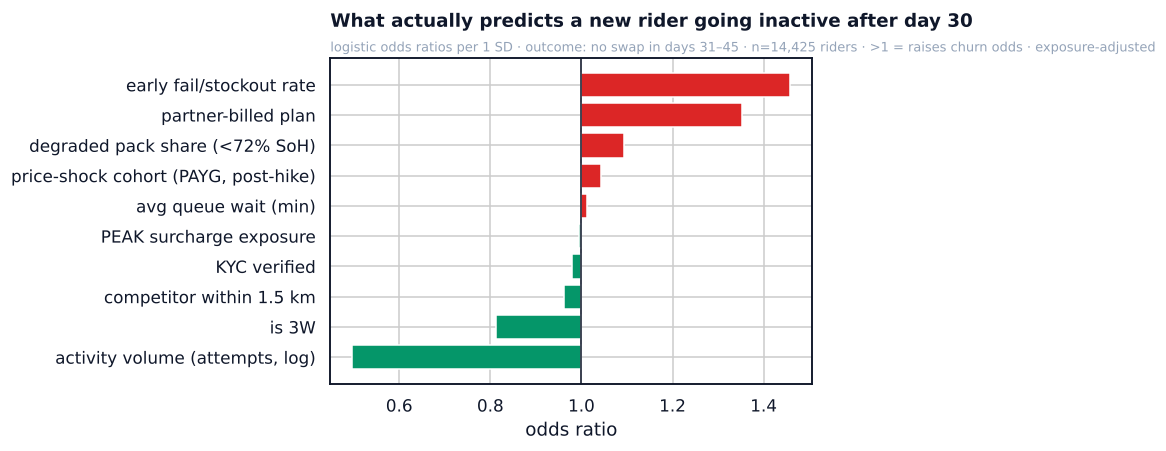

In [28]:
# ── First-14-day feature matrix + logistic regression ────────────
X = con.execute("""
WITH f14 AS (
  SELECT r.rider_id,
    COUNT(*) attempts14,
    COUNT(*) FILTER (WHERE c.event_type IN
      ('failed_no_charged_battery','abandoned_queue')) fails14,
    AVG(c.queue_wait_sec) wait14,
    COUNT(*) FILTER (WHERE c.is_completed AND c.soh_out_pct < 72) lowsoh14,
    COUNT(*) FILTER (WHERE c.is_completed) comp14,
    COUNT(*) FILTER (WHERE c.tariff_code='PEAK') peak14,
    MAX(CASE WHEN s.competitor_within_1_5km_since IS NOT NULL
         AND c.ts::DATE >= s.competitor_within_1_5km_since THEN 1 ELSE 0 END) comp_exposed
  FROM riders_c r
  JOIN swaps_clean c ON c.rider_id=r.rider_id
   AND c.ts::DATE BETWEEN r.signup_date AND r.signup_date + 14
  JOIN stations_c s USING(station_id)
  GROUP BY 1),
out AS (  -- bounded outcome: no swap in days 31–45 (fully observable for all included riders)
  SELECT r.rider_id,
    CASE WHEN COUNT(*) FILTER (WHERE c.is_completed AND c.ts::DATE
      BETWEEN r.signup_date + 31 AND r.signup_date + 45) > 0 THEN 0 ELSE 1 END churn30
  FROM riders_c r LEFT JOIN swaps_clean c USING(rider_id) GROUP BY 1, r.signup_date)
SELECT r.rider_id, r.vehicle_class, r.plan_type, r.signup_channel, r.kyc_verified,
  f.attempts14, f.fails14, COALESCE(f.wait14,0) wait14, f.lowsoh14, f.comp14,
  f.peak14, f.comp_exposed, o.churn30,
  (r.plan_type='pay_as_you_go' AND r.signup_date >= DATE '2024-07-01')::INT price_shock
FROM riders_c r JOIN f14 f USING(rider_id) JOIN out o USING(rider_id)
WHERE r.signup_date BETWEEN DATE '2024-01-01' AND DATE '2025-05-15'""").df()
print(f"model population: {len(X):,} riders · churn30 base rate "
      f"{100*X.churn30.mean():.1f}%")

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
feat = pd.DataFrame({
  "early fail/stockout rate": X.fails14/X.attempts14,
  "avg queue wait (min)": X.wait14/60,
  "degraded pack share (<72% SoH)": X.lowsoh14/X.attempts14.clip(lower=1),
  "PEAK surcharge exposure": (X.peak14>0).astype(int),
  "price-shock cohort (PAYG, post-hike)": X.price_shock,
  "competitor within 1.5 km": X.comp_exposed,
  "is 3W": (X.vehicle_class=="3W").astype(int),
  "partner-billed plan": (X.plan_type=="partner_billed").astype(int),
  "KYC verified": X.kyc_verified.astype(int),
  "activity volume (attempts, log)": np.log1p(X.attempts14),
})
sc = StandardScaler().fit(feat)
lr = LogisticRegression(max_iter=2000).fit(sc.transform(feat), X.churn30)
ors = pd.Series(np.exp(lr.coef_[0]), index=feat.columns).sort_values()
print("\nOdds ratios (per 1 SD):\n", ors.round(3).to_string())
KEY["churn_odds_ratios"] = ors.round(3).to_dict()
KEY["churn30_base_rate"] = round(100*float(X.churn30.mean()),1)

grp = X.assign(bad_start=(X.fails14>0)).groupby("bad_start").churn30.mean()*100
KEY["churn30_no_early_fail"] = round(float(grp.get(False)),1)
KEY["churn30_with_early_fail"] = round(float(grp.get(True)),1)
print(f"\nChurn-30: {KEY['churn30_no_early_fail']}% (clean first 14 days) vs "
      f"{KEY['churn30_with_early_fail']}% (≥1 stockout/abandon in first 14 days)")

fig, ax = plt.subplots(figsize=(8.5,4.2))
colors = [RED if v>1 else GREEN for v in ors.values]
ax.barh(ors.index, ors.values-1, left=1, color=colors)
ax.axvline(1, color=NAVY, lw=1)
title2(ax, "What actually predicts a new rider going inactive after day 30",
       f"logistic odds ratios per 1 SD · outcome: no swap in days 31–45 · n={len(X):,} riders · >1 = raises churn odds · exposure-adjusted")
ax.set_xlabel("odds ratio"); fig.tight_layout(); savefig(fig,"13_churn_or"); plt.show()

## 8 · The 4-way budget decision, quantified

In [29]:
# ── ROI comparison of leadership's four proposals ────────────────
cm = KEY["cm_q2_25"]                       # current contribution margin per swap (₹)

# A) Blanket Wave-3: Wave-2 realized revenue ÷ fixed-cost cover by location type
w2 = {k.split("|")[1]: v for k,v in KEY["wave_rev_to_fixed"].items()
      if k.startswith("Wave2")}
w2_best, w2_worst = max(w2, key=w2.get), min(w2, key=w2.get)

# B) Batteries: replace Kyron + convert stockouts at the margin
stockout_fails = con.execute("""SELECT COUNT(*) FROM swaps_clean
  WHERE event_type='failed_no_charged_battery'
    AND ts >= DATE '2025-01-01'""").fetchone()[0]
monthly_stockouts = stockout_fails/6
recoverable = 0.6 * monthly_stockouts          # conservative conversion assumption
battery_capex = KEY["kyron_writeoff_inr"]      # like-for-like replacement
monthly_gain_B = recoverable*cm
payback_B = (battery_capex/monthly_gain_B) if monthly_gain_B > 0 else None
pay_txt = (f"direct payback ~{payback_B:.0f} months on margin alone"
           if payback_B else
           f"margin/swap is ₹{cm:.0f} so the case rests on retention, not per-swap profit")

# C) Peak rollout economics
leak = KEY["exempt_leakage_inr"]
net_peak = con.execute("""
SELECT COUNT(*) FROM swaps_clean c JOIN stations_c s USING(station_id)
WHERE c.is_completed AND EXTRACT(hour FROM c.ts) IN (12,13,19,20,21)
  AND s.city NOT IN ('Bengaluru','Pune') AND c.ts >= DATE '2025-01-01'""").fetchone()[0]
rollout_annual = net_peak/6*12 * 15 * 0.9      # ₹15 surcharge, 10% attrition haircut

# D) ZipDrop: margin gap vs the median of the other 11 partners
others = [p["cm_after_wc"] for p in KEY["partner_table"] if p["partner_id"]!="FP-03"]
zd_gap = float(np.median(others)) - KEY["zipdrop_cm_after"]
zd_annual = zd_gap * KEY["zipdrop_monthly_swaps_after"]*12

opts = pd.DataFrame([
 ["A. Blanket Wave-3 stations",
  f"Wave-2 revenue covers {w2[w2_best]:.1f}× fixed cost at {w2_best} sites but only "
  f"{w2[w2_worst]:.1f}× at {w2_worst}; meanwhile {KEY['fail_share_top20pct_stations']:.0f}% "
  f"of failures sit at 20% of existing stations — capacity, not coverage, is the constraint",
  "NO as blanket — densify only the top-decile congested zones"],
 ["B. More batteries (replace Kyron + 3W buffer)",
  f"₹{battery_capex/1e7:.1f} Cr replaces the retired fleet; converting ~60% of "
  f"{monthly_stockouts:,.0f} monthly stockouts recovers ₹{monthly_gain_B*12/1e7:.2f} Cr/yr "
  f"of margin ({pay_txt}); stockouts also carry the single largest churn odds-ratio "
  f"({KEY['churn_odds_ratios']['early fail/stockout rate']:.2f})",
  "YES — first priority; pair with Gen-1 charger upgrades at hot hubs (91.8 vs 42.2 min charge)"],
 ["C. Network-wide peak pricing",
  f"Pilot DiD shows peak share moved {KEY['did_peak_share_pp']:+.1f} pp — it's revenue, not "
  f"load-shifting; surcharge-exempt B2B free-rode {KEY['exempt_peak_swaps_pilot']:,} peak swaps "
  f"(₹{leak/1e5:.1f} L) in-pilot. Billable rollout ≈ ₹{rollout_annual/1e7:.1f} Cr/yr",
  "YES after closing the exemption + funding a real off-peak rebate"],
 ["D. Exclusive with ZipDrop",
  f"ZipDrop CM ₹{KEY['zipdrop_cm_after']:.1f}/swap vs median partner "
  f"₹{float(np.median(others)):.1f} → gap ₹{zd_gap:.1f}/swap ≈ ₹{zd_annual/1e7:.2f} Cr/yr; "
  f"plus 45-day terms and surcharge exemption; realized discount "
  f"{KEY['zipdrop_disc_pct_before']:.1f}% → {KEY['zipdrop_disc_pct_after']:.1f}% (see §6)",
  "NO at current terms — renegotiate: off-peak volume tiers, surcharge billable, ≤30-day terms"],
], columns=["Proposal","Evidence","Verdict"])
print(opts.to_string(index=False))
KEY["budget_matrix"] = opts.to_dict("records")
KEY["battery_margin_gain_annual_inr"] = float(monthly_gain_B*12)
KEY["battery_payback_months"] = round(float(payback_B),1) if payback_B else None
KEY["rollout_annual_inr"] = float(rollout_annual)
KEY["zipdrop_gap_per_swap"] = round(zd_gap,2)
KEY["zipdrop_annual_gap_inr"] = float(zd_annual)
KEY["monthly_stockouts_2025"] = round(float(monthly_stockouts))

                                     Proposal                                                                                                                                                                                                                     Evidence                                                                                      Verdict
                   A. Blanket Wave-3 stations                            Wave-2 revenue covers 8.3× fixed cost at commercial_hub sites but only 3.0× at transit_hub; meanwhile 42% of failures sit at 20% of existing stations — capacity, not coverage, is the constraint                                  NO as blanket — densify only the top-decile congested zones
B. More batteries (replace Kyron + 3W buffer) ₹4.8 Cr replaces the retired fleet; converting ~60% of 11,624 monthly stockouts recovers ₹0.07 Cr/yr of margin (direct payback ~884 months on margin alone); stockouts also carry the single largest churn odds-ratio (1.46) YES — first p

## 9 · Executive summary figure (LinkedIn export)

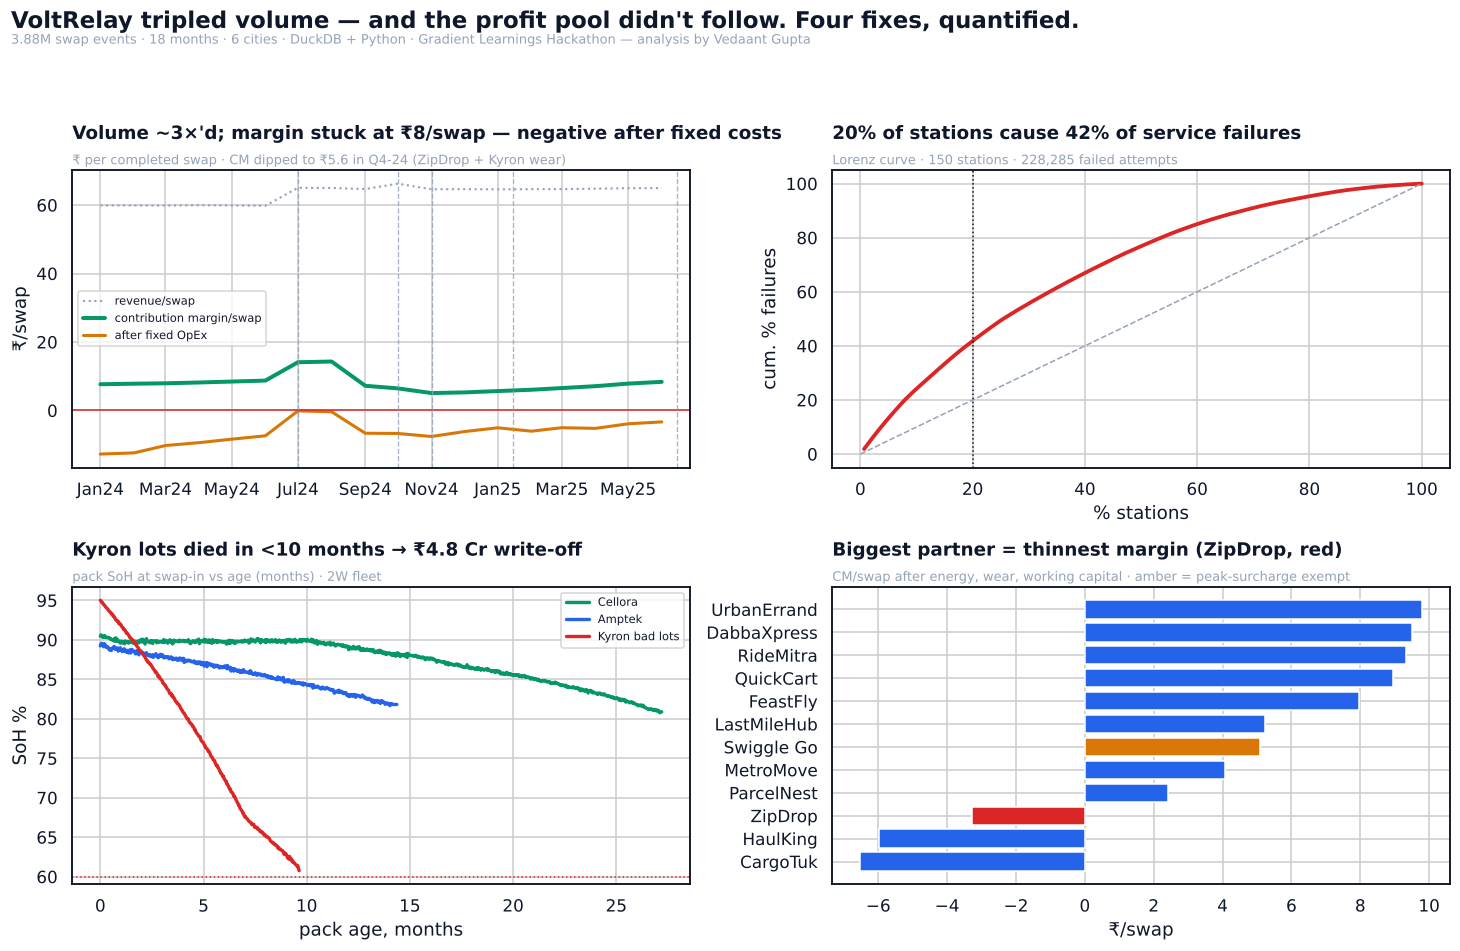

saved VoltRelay_Executive_Summary_LinkedIn.png


In [30]:
# ── 2×2 dashboard → VoltRelay_Executive_Summary_LinkedIn.png ─────
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.6))
fig.patch.set_facecolor("white")

ax = axes[0,0]   # margin compression
ax.plot(monthly.m, monthly.rev_per_swap, color=GREY, lw=1.4, ls=":", label="revenue/swap")
ax.plot(monthly.m, monthly.cm_per_swap, color=GREEN, lw=2.6, label="contribution margin/swap")
ax.plot(monthly.m, monthly.op_per_swap, color=AMBER, lw=2, label="after fixed OpEx")
ax.axhline(0,color=RED,lw=1); add_milestones(ax, labels=False)
title2(ax, f"Volume ~3×'d; margin stuck at ₹{KEY['cm_q2_25']:.0f}/swap — negative after fixed costs",
       f"₹ per completed swap · CM dipped to ₹{KEY['cm_q4_24']:.1f} in Q4-24 (ZipDrop + Kyron wear)")
ax.legend(fontsize=7.5); ax.set_ylabel("₹/swap")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b%y"))

ax = axes[0,1]   # Lorenz
ax.plot(stn_fail.stn_share, stn_fail.cum_fail_share, color=RED, lw=2.5)
ax.plot([0,100],[0,100], color=GREY, ls="--", lw=1)
ax.axvline(20, color=NAVY, ls=":", lw=1)
title2(ax, f"20% of stations cause {KEY['fail_share_top20pct_stations']:.0f}% of service failures",
       f"Lorenz curve · {KEY['n_stations']} stations · {KEY['failed_attempts']:,} failed attempts")
ax.set_xlabel("% stations"); ax.set_ylabel("cum. % failures")

ax = axes[1,0]   # Kyron decay
for coh, c in [("Cellora",GREEN),("Amptek",BLUE),("Kyron bad lots",RED)]:
    d = decay[decay.cohort==coh].groupby("age_months").soh.mean()
    if len(d): ax.plot(d.index, d.values, lw=2.2, color=c, label=coh)
ax.axhline(60, color=RED, ls=":", lw=1)
title2(ax, f"Kyron lots died in <10 months → ₹{KEY['kyron_writeoff_inr']/1e7:.1f} Cr write-off",
       "pack SoH at swap-in vs age (months) · 2W fleet")
ax.set_xlabel("pack age, months"); ax.set_ylabel("SoH %"); ax.legend(fontsize=7.5)

ax = axes[1,1]   # partner margins
ps = part.sort_values("cm_after_wc")
cols = [RED if p=="FP-03" else (AMBER if b=="N" else BLUE)
        for p,b in zip(ps.partner_id, ps.peak_surcharge_billable)]
ax.barh(ps.partner_name, ps.cm_after_wc, color=cols)
title2(ax, "Biggest partner = thinnest margin (ZipDrop, red)",
       "CM/swap after energy, wear, working capital · amber = peak-surcharge exempt")
ax.set_xlabel("₹/swap")

head = ("VoltRelay tripled volume — and the profit pool didn't follow. Four fixes, quantified."
        if KEY['m_op_profit']['2025-06'] < 0 else
        "VoltRelay tripled volume — here's where the margin leaks. Four fixes, quantified.")
fig.suptitle(head,
             fontsize=15, fontweight="bold", color=NAVY, x=0.02, ha="left", y=1.0)
fig.text(0.02, 0.965, "3.88M swap events · 18 months · 6 cities · DuckDB + Python · "
         "Gradient Learnings Hackathon — analysis by Vedaant Gupta",
         fontsize=8.5, color=GREY)
fig.tight_layout(rect=[0,0,1,0.94])
fig.savefig("VoltRelay_Executive_Summary_LinkedIn.png", dpi=200, bbox_inches="tight")
plt.show(); print("saved VoltRelay_Executive_Summary_LinkedIn.png")

In [31]:
# ── Persist every headline number for the written deliverables ───
def clean(o):
    if isinstance(o,dict): return {str(k):clean(v) for k,v in o.items()}
    if isinstance(o,(list,tuple)): return [clean(v) for v in o]
    if isinstance(o,(np.integer,)): return int(o)
    if isinstance(o,(np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o,pd.Timestamp): return str(o.date())
    return o
with open("key_numbers.json","w") as f: json.dump(clean(KEY), f, indent=1, default=str)
print(f"{len(KEY)} key figures saved → key_numbers.json")
con.close()

82 key figures saved → key_numbers.json
